# Vente croisée : assurance santé → assurance automobile

**Données** : [Kaggle - Health Insurance Cross Sell Prediction](https://www.kaggle.com/datasets/anmolkumar/health-insurance-cross-sell-prediction) (381 109 clients, 12 variables, avec des valeurs manquantes).

**Question** : parmi les clients d'une assurance santé, lesquels seraient intéressés par une assurance automobile ? L'objectif est de mieux cibler les campagnes commerciales.

**Variable cible** : `Response` (1 = intéressé, 0 = non intéressé).

### Démarche (CRISP-DM)
1. Compréhension métier et des données
2. Analyse exploratoire
3. Préparation : séparation train/test **avant** tout apprentissage, imputation, nouvelles variables, encodage
4. Rééquilibrage : chaque méthode est réglée puis comparée par validation croisée
5. Sélection de variables : filtres communs, puis une méthode adaptée à chaque modèle
6. Modèles par défaut (point de départ)
7. Réglage des hyperparamètres de chaque modèle et choix du seuil de décision
8. Interprétation : importance par permutation, SHAP, LIME, contrefactuels
9. Évaluation finale sur le jeu de test et conclusion

**Reproductibilité** : une seule graine (`SEED = 42`) est utilisée partout (découpage, rééquilibrage, modèles, recherches d'hyperparamètres, SHAP, LIME). Deux exécutions donnent les mêmes résultats.

In [1]:
# ============================================================
# IMPORTS ET CONFIGURATION
# ============================================================
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint
from collections import Counter

from sklearn import set_config
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, TargetEncoder, LabelEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_validate)
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.feature_selection import f_classif, mutual_info_classif, RFECV, SequentialFeatureSelector
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC, ADASYN
from imblearn.under_sampling import RandomUnderSampler

import shap
from lime.lime_tabular import LimeTabularExplainer

# Reproductibilite : une seule graine pour tout le notebook
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
CV5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
print('Bibliotheques importees, graine fixee a', SEED)

Bibliotheques importees, graine fixee a 42


**Interprétation :** cette cellule importe les bibliothèques et fixe une graine unique. Toutes les validations croisées utilisent les mêmes découpages (`CV5`, `CV3`), ce qui rend les comparaisons entre méthodes équitables et les résultats reproductibles.

---
## 1. Comprehension Metier & Donnees <a id='1-comprehension'></a>

### Objectif Metier
Une compagnie d'assurance sante veut **cross-seller** une assurance automobile a ses clients existants. Le but est d'identifier les clients les plus susceptibles d'acheter pour optimiser les campagnes marketing.

### Description des Variables

| Variable | Description | Type |
|----------|-------------|------|
| `id` | Identifiant unique | Num | 
| `Gender` | Genre (Male/Female) | Cat | 
| `Age` | Age du client | Num | 
| `Driving_License` | Permis (0/1) | Bin | 
| `Region_Code` | Code regional | Num | 
| `Previously_Insured` | Deja assure (0/1) | Bin |
| `Vehicle_Age` | Age vehicule | Cat |
| `Vehicle_Damage` | Endommage (Yes/No) | Cat | 
| `Annual_Premium` | Prime annuelle | Num |
| `Policy_Sales_Channel` | Canal vente | Num | 
| `Vintage` | Anciennete (jours) | Num |
| **`Response`** | **Interet (0/1)** | **Bin** |

**Problematique** : Classification binaire desequilibree (~88% vs ~12%)

In [2]:
# ============================================================
# CHARGEMENT DES DONNEES
# ============================================================
train_path = 'train.csv'  # fichier à télécharger sur Kaggle (voir README)

df = pd.read_csv(train_path)

print('=' * 60)
print('APERcu DES DONNEES')
print('=' * 60)
print('Dimensions :', df.shape[0], 'lignes x', df.shape[1], 'colonnes')
print('Colonnes :', list(df.columns))
print('' + str(df.head()))

# Identification des types de variables
cat_features = ['Gender', 'Vehicle_Age', 'Vehicle_Damage']
num_features = ['Age', 'Annual_Premium', 'Vintage', 'Region_Code', 'Policy_Sales_Channel']
bin_features = ['Driving_License', 'Previously_Insured']
target = 'Response'

print('Variables categoriques :', cat_features)
print('Variables numeriques :', num_features)
print('Variables binaires :', bin_features)
print('Cible :', target)

APERcu DES DONNEES
Dimensions : 381109 lignes x 12 colonnes
Colonnes : ['id', 'Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage', 'Response']
   id  Gender   Age  Driving_License  Region_Code  Previously_Insured  \
0   1    Male  44.0              1.0         28.0                 0.0   
1   2     NaN  76.0              1.0          3.0                 0.0   
2   3    Male  47.0              1.0         28.0                 0.0   
3   4    Male  21.0              1.0          NaN                 1.0   
4   5  Female  29.0              1.0         41.0                 1.0   

  Vehicle_Age Vehicle_Damage  Annual_Premium  Policy_Sales_Channel  Vintage  \
0   > 2 Years            Yes         40454.0                  26.0    217.0   
1    1-2 Year             No         33536.0                  26.0    183.0   
2   > 2 Years            Yes         38294.0                  26.0     27.0

**Interprétation :** cette cellule charge le fichier `train.csv`, affiche les premieres lignes et met en place le jeu de donnees de travail.

In [3]:
# ============================================================
# INFORMATIONS STRUCTURELLES
# ============================================================
print('Types des variables :')
print(df.dtypes)
print('' + '-'*50)

print('Valeurs manquantes :')
missing = df.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else 'Aucune valeur manquante !')
print('' + '-'*50)
print("=" * 55)
print("AVANT PRÉTRAITEMENT")
print("=" * 55)
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes\n")
print("Valeurs manquantes par colonne :")
missing = df.isnull().sum()
pct     = (missing / len(df) * 100).round(2)
summary = pd.DataFrame({"Manquantes": missing, "Pourcentage (%)": pct})
print(summary[summary["Manquantes"] > 0].to_string())

print('Doublons :', df.duplicated().sum())
print('' + '-'*50)

print('Statistiques descriptives :')
print(df.describe())

Types des variables :
id                        int64
Gender                   object
Age                     float64
Driving_License         float64
Region_Code             float64
Previously_Insured      float64
Vehicle_Age              object
Vehicle_Damage           object
Annual_Premium          float64
Policy_Sales_Channel    float64
Vintage                 float64
Response                  int64
dtype: object
--------------------------------------------------
Valeurs manquantes :
Gender                  11433
Age                     19055
Driving_License          7622
Region_Code             26677
Previously_Insured      19055
Vehicle_Age             15244
Vehicle_Damage          11433
Annual_Premium          22866
Policy_Sales_Channel    30488
Vintage                 15244
dtype: int64
--------------------------------------------------
AVANT PRÉTRAITEMENT
Dimensions : 381109 lignes × 12 colonnes

Valeurs manquantes par colonne :
                      Manquantes  Pourcentage (%)

                  id            Age  Driving_License    Region_Code  \
count  381109.000000  362054.000000    373487.000000  354432.000000   
mean   190555.000000      38.813694         0.997874      26.388977   
std    110016.836208      15.509288         0.046059      13.228665   
min         1.000000      20.000000         0.000000       0.000000   
25%     95278.000000      25.000000         1.000000      15.000000   
50%    190555.000000      36.000000         1.000000      28.000000   
75%    285832.000000      49.000000         1.000000      35.000000   
max    381109.000000      85.000000         1.000000      52.000000   

       Previously_Insured  Annual_Premium  Policy_Sales_Channel  \
count       362054.000000   358243.000000         350621.000000   
mean             0.458238    30558.771661            112.059879   
std              0.498254    17211.843881             54.191192   
min              0.000000     2630.000000              1.000000   
25%              0.000000

**Interprétation :** cette cellule resume la structure du jeu de donnees, notamment les types de variables et les informations utiles pour la preparation.

---
## 2. Analyse Exploratoire des Donnees (EDA) <a id='2-eda'></a>

L'EDA vise a :
- Comprendre la distribution des variables
- Identifier les relations avec la cible
- Detecter les anomalies et outliers
- Guider le feature engineering

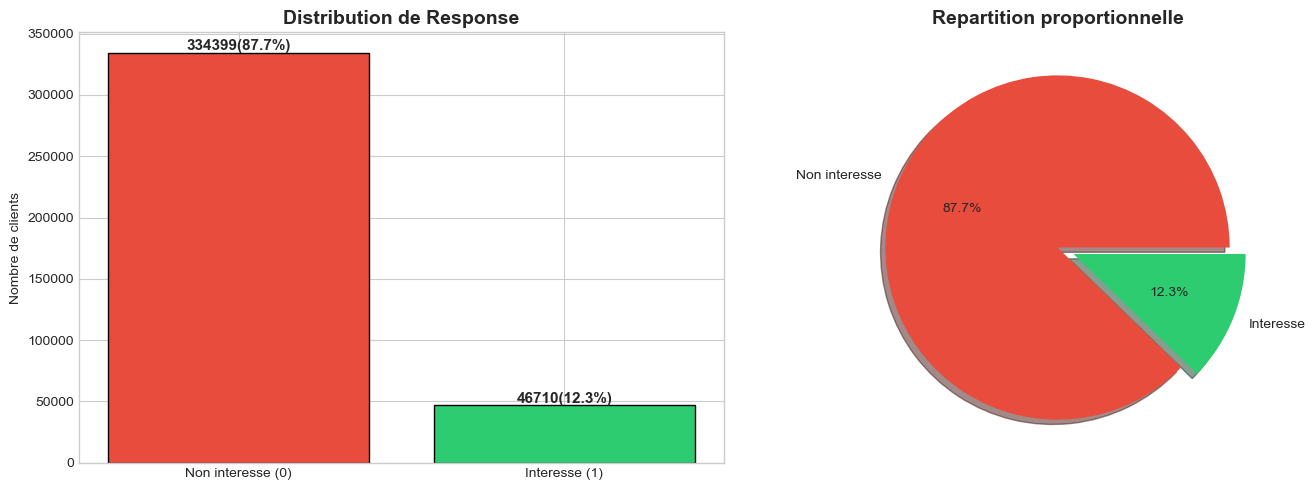

INTERPRETATION :
Dataset fortement DESEQUILIBRE : 12.3 % de la classe minoritaire (Response=1)
Cela necessite des techniques de reequilibrage (SMOTE, sous-echantillonnage, etc.)


In [4]:
# ============================================================
# 2.1 DISTRIBUTION DE LA VARIABLE CIBLE
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

response_counts = df['Response'].value_counts()
colors = ['#e74c3c', '#2ecc71']

axes[0].bar(['Non interesse (0)', 'Interesse (1)'], response_counts.values,
            color=colors, edgecolor='black')
axes[0].set_title('Distribution de Response', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Nombre de clients')
for i, v in enumerate(response_counts.values):
    axes[0].text(i, v + 2000, str(v) + '(' + str(round(v/len(df)*100,1)) + '%)',
                ha='center', fontsize=11, fontweight='bold')

axes[1].pie(response_counts.values, labels=['Non interesse', 'Interesse'],
            autopct='%1.1f%%', colors=colors, explode=(0, 0.1), shadow=True)
axes[1].set_title('Repartition proportionnelle', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('eda_target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

print('INTERPRETATION :')
print('Dataset fortement DESEQUILIBRE :', round(response_counts[1]/len(df)*100,1),
      '% de la classe minoritaire (Response=1)')
print('Cela necessite des techniques de reequilibrage (SMOTE, sous-echantillonnage, etc.)')

**Interprétation :** cette cellule montre que la cible est desequilibree, ce qui justifie ensuite des techniques de reequilibrage et des metriques adaptees.

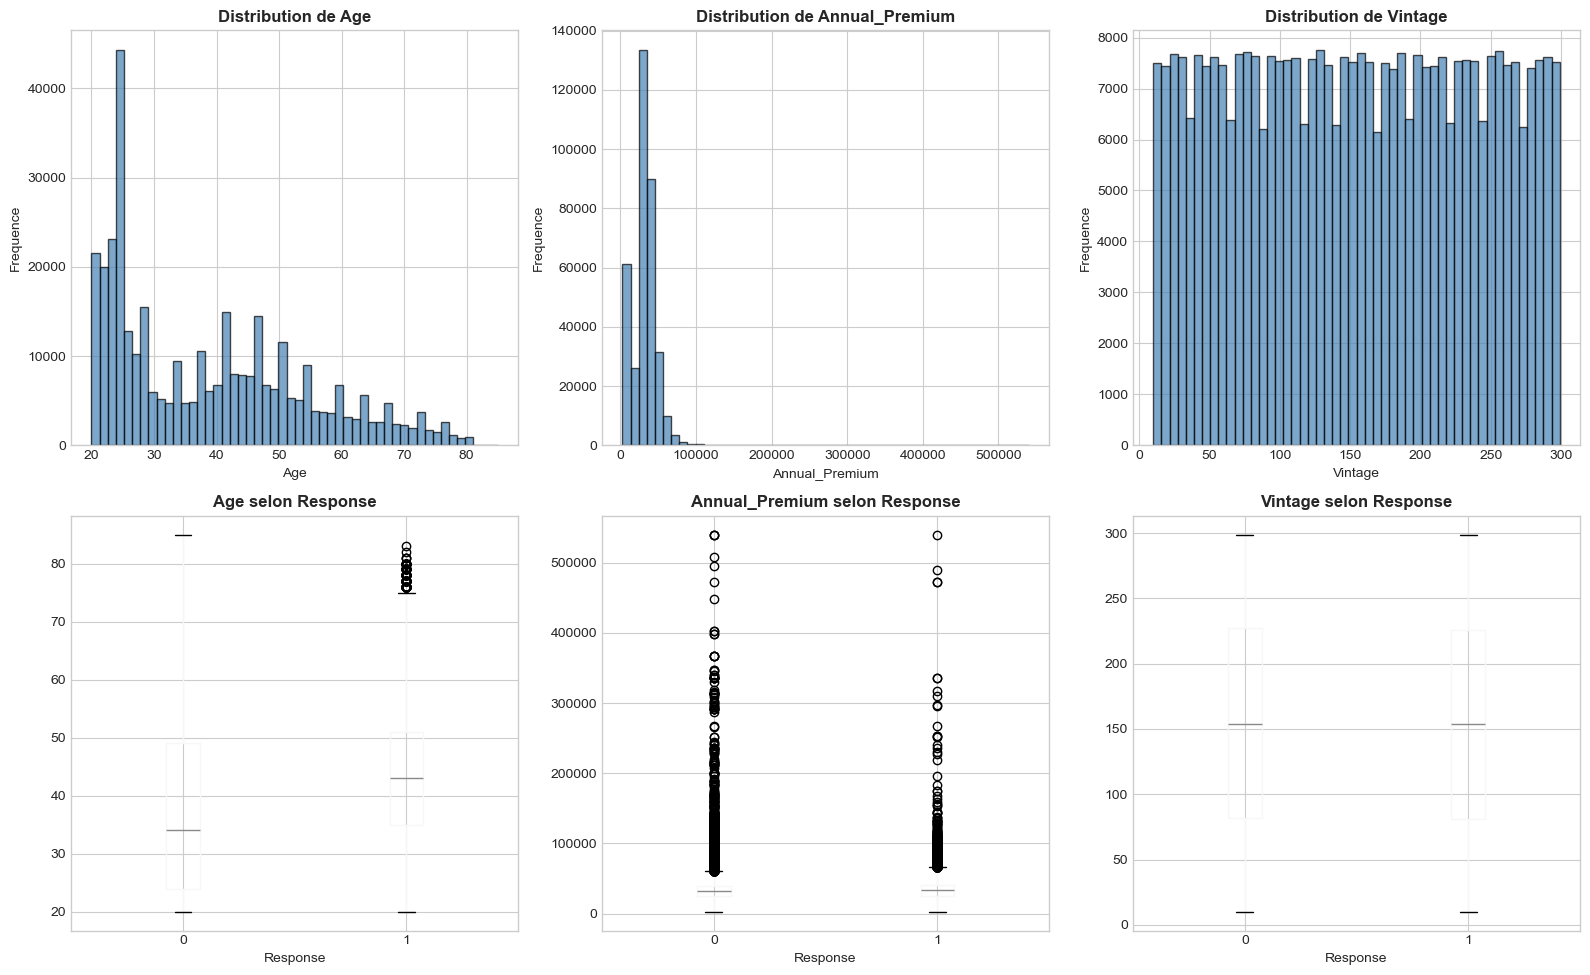

INTERPRETATION :
- Age : Distribution 20-80 ans, les interesses semblent plus jeunes
- Annual_Premium : Concentre autour de 30K, outliers a 100K+
- Vintage : Uniforme 10-300 jours


In [5]:
# ============================================================
# 2.2 ANALYSE DES VARIABLES NUMERIQUES
# ============================================================
numeric_cols = ['Age', 'Annual_Premium', 'Vintage']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for i, col in enumerate(numeric_cols):
    axes[0, i].hist(df[col], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, i].set_title('Distribution de ' + col, fontweight='bold')
    axes[0, i].set_xlabel(col)
    axes[0, i].set_ylabel('Frequence')

    df.boxplot(column=col, by='Response', ax=axes[1, i])
    axes[1, i].set_title(col + ' selon Response', fontweight='bold')
    axes[1, i].set_xlabel('Response')

plt.suptitle('', fontsize=0)
plt.tight_layout()
plt.savefig('eda_numeric_variables.png', dpi=150, bbox_inches='tight')
plt.show()

print('INTERPRETATION :')
print('- Age : Distribution 20-80 ans, les interesses semblent plus jeunes')
print('- Annual_Premium : Concentre autour de 30K, outliers a 100K+')
print('- Vintage : Uniforme 10-300 jours')

**Interprétation :** cette cellule examine la distribution des variables numeriques et leur relation potentielle avec la cible.

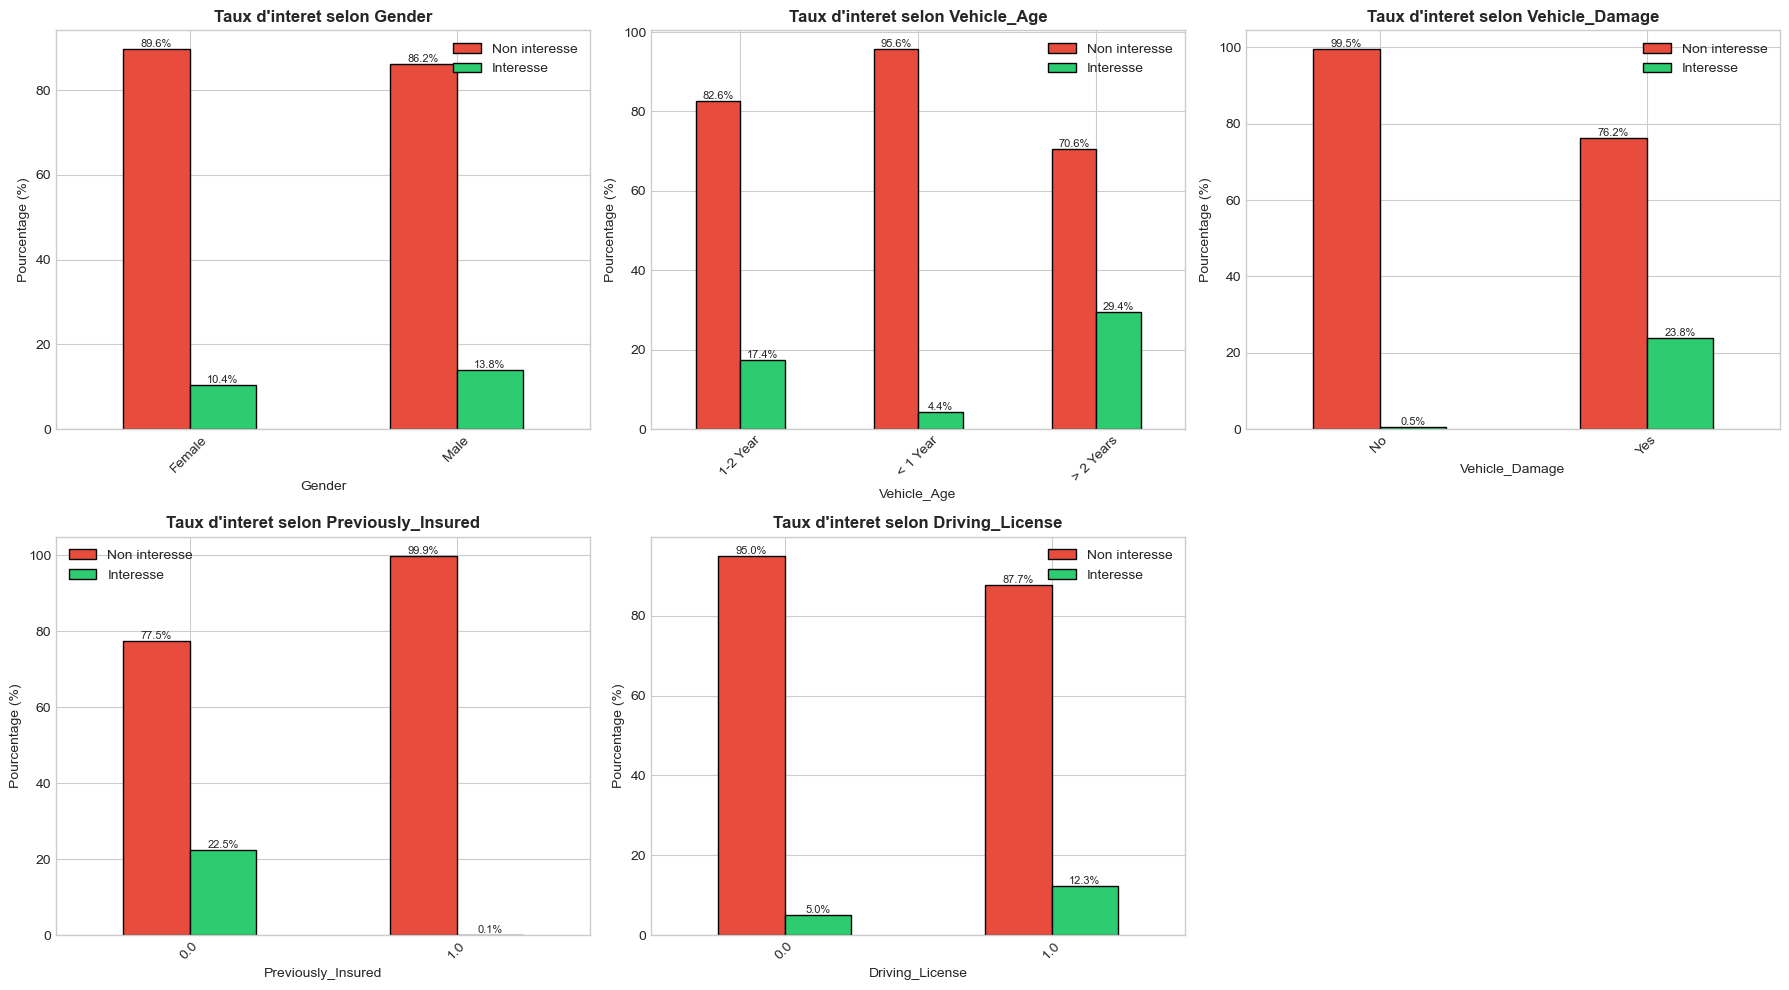

INTERPRETATION CLE :
* Vehicle_Damage=Yes : ~25% interesses vs ~1% pour No -> TRES DISCRIMINANT
* Previously_Insured=0 : ~23% interesses vs ~1% pour 1 -> TRES DISCRIMINANT
* Vehicle_Age ancien > interet que neuf
* Gender : Faible pouvoir discriminant


In [6]:
# ============================================================
# 2.3 ANALYSE DES VARIABLES CATEGORIQUES
# ============================================================
cat_cols = ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Previously_Insured', 'Driving_License']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    crosstab = pd.crosstab(df[col], df['Response'], normalize='index') * 100
    crosstab.plot(kind='bar', ax=axes[i], color=['#e74c3c', '#2ecc71'], edgecolor='black')
    axes[i].set_title("Taux d'interet selon " + col, fontweight='bold', fontsize=12)
    axes[i].set_ylabel('Pourcentage (%)')
    axes[i].legend(['Non interesse', 'Interesse'])
    axes[i].tick_params(axis='x', rotation=45)

    for container in axes[i].containers:
        axes[i].bar_label(container, fmt='%.1f%%', fontsize=8)

if len(cat_cols) < len(axes):
    axes[-1].axis('off')

plt.tight_layout()
plt.savefig('eda_categorical_variables.png', dpi=150, bbox_inches='tight')
plt.show()

print('INTERPRETATION CLE :')
print('* Vehicle_Damage=Yes : ~25% interesses vs ~1% pour No -> TRES DISCRIMINANT')
print('* Previously_Insured=0 : ~23% interesses vs ~1% pour 1 -> TRES DISCRIMINANT')
print('* Vehicle_Age ancien > interet que neuf')
print('* Gender : Faible pouvoir discriminant')

**Interprétation :** cette cellule compare les categories principales et aide a voir si certains profils clients sont plus associes a la cible.

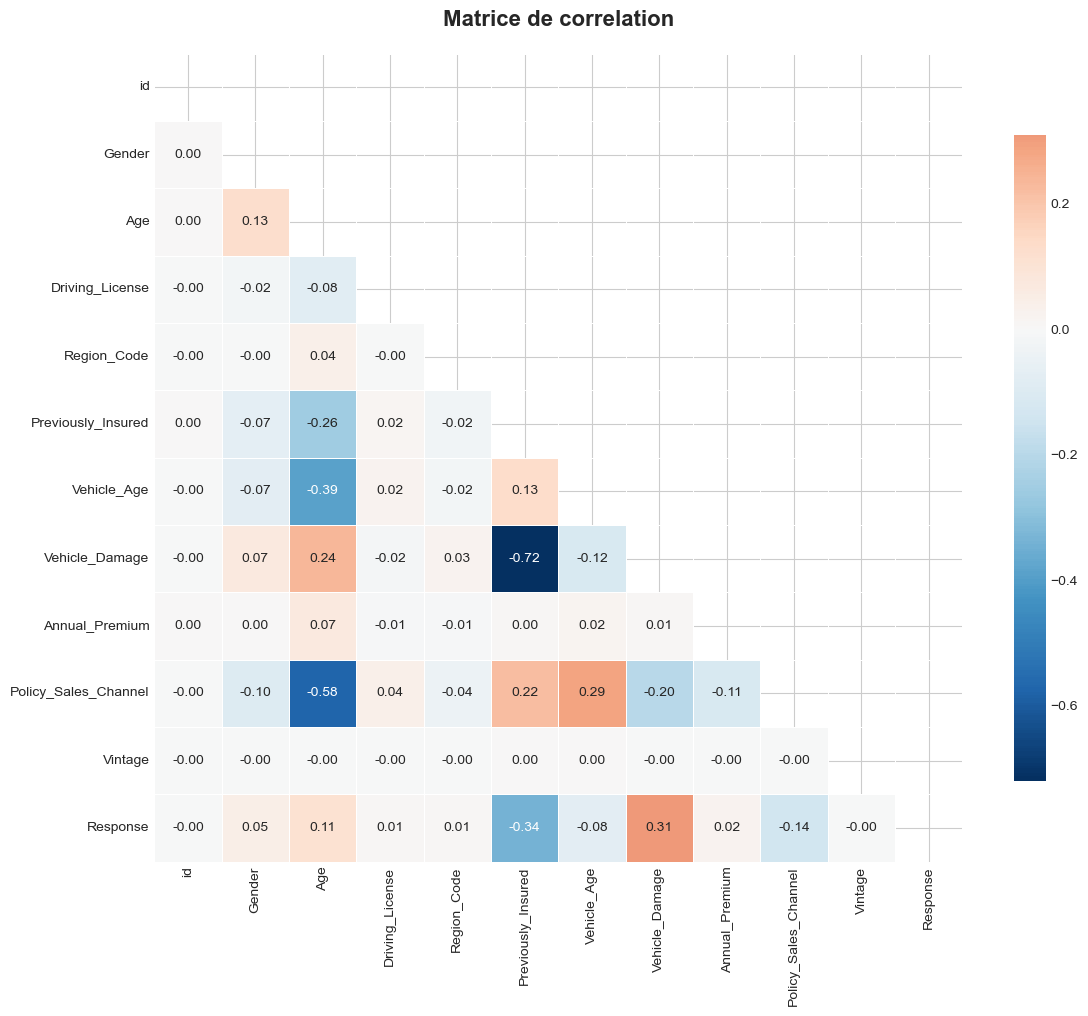

CORRELATIONS AVEC LA CIBLE (Response) :
  Vehicle_Damage            : +0.3098
  Age                       : +0.1113
  Gender                    : +0.0464
  Annual_Premium            : +0.022
  Region_Code               : +0.0103
  Driving_License           : +0.0102
  Vintage                   : -0.001
  id                        : -0.0014
  Vehicle_Age               : -0.0796
  Policy_Sales_Channel      : -0.1392
  Previously_Insured        : -0.3411


In [7]:
# ============================================================
# 2.4 MATRICE DE CORRELATION
# ============================================================
df_corr = df.copy()
le = LabelEncoder()
for col in cat_features:
    df_corr[col] = le.fit_transform(df_corr[col])

corr_matrix = df_corr.corr()

plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Matrice de correlation', fontsize=16, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('eda_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print('CORRELATIONS AVEC LA CIBLE (Response) :')
corr_target = corr_matrix['Response'].sort_values(ascending=False)
for var, corr in corr_target.items():
    if var != 'Response':
        print('  ' + var.ljust(25) + ' : ' + ('+' if corr >= 0 else '') + str(round(corr,4)))

**Interprétation :** cette cellule encode les variables categorielle pour calculer une correlation exploitable et identifier les liens lineaires avec la cible.

---
## 3. Préparation des données

L'ordre compte : on sépare d'abord un jeu de **test (20 %)** qui ne sert qu'à l'évaluation finale. Tout ce qui s'apprend à partir des données (valeurs d'imputation, encodages, sélection de variables, rééquilibrage, hyperparamètres, seuil de décision) est appris **uniquement sur le train**. Sinon, le test « fuit » dans le modèle et les scores sont trop optimistes.

In [8]:
# ============================================================
# 3.1 SEPARATION TRAIN / TEST (avant tout apprentissage)
# ============================================================
X = df.drop(columns=['id', 'Response'])
y = df['Response'].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Train :', X_train_raw.shape[0], 'clients | taux d interet =', round(y_train.mean() * 100, 2), '%')
print('Test  :', X_test_raw.shape[0], 'clients | taux d interet =', round(y_test.mean() * 100, 2), '%')

Train : 304887 clients | taux d interet = 12.26 %
Test  : 76222 clients | taux d interet = 12.26 %


In [9]:
# ============================================================
# 3.2 IMPUTATION DES VALEURS MANQUANTES (apprise sur le train)
# ============================================================
# Numerique continue -> mediane ; numerique discrete / binaire -> mode ; categorielle -> mode
cols_continues = ['Age', 'Annual_Premium']
cols_discretes = ['Driving_License', 'Region_Code', 'Previously_Insured', 'Policy_Sales_Channel', 'Vintage']
cols_categorielles = ['Gender', 'Vehicle_Age', 'Vehicle_Damage']

print('Valeurs manquantes dans le train (%) :')
print((X_train_raw.isna().mean() * 100).round(2).to_string())

imputers = [(SimpleImputer(strategy='median'), cols_continues),
            (SimpleImputer(strategy='most_frequent'), cols_discretes),
            (SimpleImputer(strategy='most_frequent'), cols_categorielles)]

X_train_imp, X_test_imp = X_train_raw.copy(), X_test_raw.copy()
rows = []
for imputer, cols in imputers:
    X_train_imp[cols] = imputer.fit_transform(X_train_raw[cols])
    X_test_imp[cols] = imputer.transform(X_test_raw[cols])
    rows += [(c, imputer.strategy, v) for c, v in zip(cols, imputer.statistics_)]
for cols in (cols_continues, cols_discretes):
    X_train_imp[cols] = X_train_imp[cols].astype(float)
    X_test_imp[cols] = X_test_imp[cols].astype(float)

print('\nValeurs d imputation apprises sur le train :')
print(pd.DataFrame(rows, columns=['Variable', 'Strategie', 'Valeur']).to_string(index=False))
print('\nValeurs manquantes restantes : train =', int(X_train_imp.isna().sum().sum()),
      '| test =', int(X_test_imp.isna().sum().sum()))

Valeurs manquantes dans le train (%) :
Gender                  2.98
Age                     5.00
Driving_License         1.98
Region_Code             6.96
Previously_Insured      4.99
Vehicle_Age             4.03
Vehicle_Damage          3.01
Annual_Premium          5.99
Policy_Sales_Channel    8.00
Vintage                 3.98



Valeurs d imputation apprises sur le train :
            Variable     Strategie   Valeur
                 Age        median     36.0
      Annual_Premium        median  31698.0
     Driving_License most_frequent      1.0
         Region_Code most_frequent     28.0
  Previously_Insured most_frequent      0.0
Policy_Sales_Channel most_frequent    152.0
             Vintage most_frequent     73.0
              Gender most_frequent     Male
         Vehicle_Age most_frequent 1-2 Year
      Vehicle_Damage most_frequent      Yes

Valeurs manquantes restantes : train = 0 | test = 0


**Interprétation :** les valeurs d'imputation (médiane ou mode) sont calculées sur le train puis appliquées telles quelles au test. Le test n'influence donc pas la préparation.

---
## 4. Nouvelles variables et encodage

Variables créées à partir de l'intuition métier :
- **Damage_NoInsurance** : véhicule déjà endommagé **et** pas encore assuré (le profil le plus prometteur)
- **Premium_per_Age** : prime rapportée à l'âge
- **Log_Premium** : logarithme de la prime, pour réduire l'asymétrie
- **Age_Group** : tranche d'âge (1 = moins de 25 ans, 5 = plus de 55 ans)

La variable `Vintage_Years` de la première version a été retirée : c'est `Vintage / 365`, elle n'apporte aucune information nouvelle.

Encodage :
- `Gender`, `Vehicle_Age`, `Vehicle_Damage` : **one-hot**
- `Region_Code` (53 régions) et `Policy_Sales_Channel` (155 canaux) : ce sont des **codes**, pas des quantités. Ils sont remplacés par un **encodage par la cible** (taux d'intérêt moyen de la région ou du canal), calculé en validation croisée interne pour éviter le surapprentissage.

L'encodeur est placé **dans le pipeline** de chaque modèle : il est réappris à chaque pli de validation croisée.

In [10]:
# ============================================================
# 4.1 CREATION DE NOUVELLES VARIABLES
# ============================================================
def add_features(d):
    d = d.copy()
    damage = (d['Vehicle_Damage'] == 'Yes').astype(int)
    d['Damage_NoInsurance'] = damage * (1 - d['Previously_Insured'])
    d['Premium_per_Age'] = d['Annual_Premium'] / (d['Age'] + 1)
    d['Log_Premium'] = np.log1p(d['Annual_Premium'])
    d['Age_Group'] = pd.cut(d['Age'], bins=[0, 25, 35, 45, 55, 120], labels=False) + 1
    return d

X_train_fe = add_features(X_train_imp)
X_test_fe = add_features(X_test_imp)

print('Taux d interet selon Damage_NoInsurance (train) :')
print((y_train.groupby(X_train_fe['Damage_NoInsurance']).mean() * 100).round(2).to_string())

Taux d interet selon Damage_NoInsurance (train) :
Damage_NoInsurance
0.0     0.52
1.0    24.83


In [11]:
# ============================================================
# 4.2 ENCODAGE (one-hot + encodage par la cible)
# ============================================================
encoder = ColumnTransformer(
    [('onehot', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'),
      ['Gender', 'Vehicle_Age', 'Vehicle_Damage']),
     ('cible', TargetEncoder(target_type='binary', random_state=SEED),
      ['Region_Code', 'Policy_Sales_Channel'])],
    remainder='passthrough', verbose_feature_names_out=False).set_output(transform='pandas')

# Version encodee du train, utilisee seulement pour la selection de variables
X_train_enc = clone(encoder).set_output(transform='pandas').fit_transform(X_train_fe, y_train)
features_all = [str(c) for c in X_train_enc.columns]

# Variables binaires ou ordinales (traitees comme categorielles par SMOTENC)
binary_like = [c for c in features_all if c.startswith(('Gender_', 'Vehicle_Age_', 'Vehicle_Damage_'))] + \
              ['Driving_License', 'Previously_Insured', 'Damage_NoInsurance', 'Age_Group']

print(len(features_all), 'variables apres encodage :')
print(features_all)


def make_pipe(model, cols, sampler='passthrough', scale=True):
    # encodage -> choix des colonnes -> standardisation -> reequilibrage -> modele
    steps = [('encode', clone(encoder).set_output(transform='pandas')),
             ('select', ColumnTransformer([('keep', 'passthrough', list(cols))], remainder='drop',
                                          verbose_feature_names_out=False).set_output(transform='pandas'))]
    steps.append(('scale', StandardScaler().set_output(transform='pandas') if scale else 'passthrough'))
    steps.append(('sampler', sampler))
    steps.append(('model', model))
    return Pipeline(steps)


def smotenc_for(cols, **kw):
    cat_idx = [i for i, c in enumerate(cols) if c in binary_like]
    return SMOTENC(categorical_features=cat_idx, random_state=SEED, **kw)

16 variables apres encodage :
['Gender_Male', 'Vehicle_Age_1-2 Year', 'Vehicle_Age_< 1 Year', 'Vehicle_Age_> 2 Years', 'Vehicle_Damage_Yes', 'Region_Code', 'Policy_Sales_Channel', 'Age', 'Driving_License', 'Previously_Insured', 'Annual_Premium', 'Vintage', 'Damage_NoInsurance', 'Premium_per_Age', 'Log_Premium', 'Age_Group']


**Interprétation :** `make_pipe` assemble toutes les étapes dans un seul objet. En validation croisée, l'encodage, la standardisation et le rééquilibrage sont donc réappris sur chaque pli d'entraînement et ne voient jamais le pli de validation. C'est ce qui garantit des scores honnêtes.

---
## 5. Rééquilibrage : chaque méthode dans sa meilleure version

Seuls 12,3 % des clients sont intéressés. Chaque méthode est d'abord **réglée** (ses paramètres sont choisis par validation croisée à 5 plis), puis les méthodes sont comparées dans leur meilleure version. Le modèle de référence est une régression logistique.

| Méthode | Principe | Paramètres réglés |
|---|---|---|
| Aucun | données brutes | aucun |
| Pondération des classes | erreurs sur les intéressés plus coûteuses | `class_weight='balanced'` |
| RandomUnderSampler | retire des non-intéressés au hasard | ratio final (0,25 / 0,5 / 1) |
| SMOTE | crée des intéressés par interpolation entre voisins | nombre de voisins (3 / 5 / 10), ratio (0,5 / 1) |
| SMOTENC | SMOTE qui respecte les variables catégorielles | nombre de voisins (3 / 5 / 10) |
| ADASYN | SMOTE concentré sur les cas difficiles | nombre de voisins (3 / 5 / 10) |

Le rééquilibrage est appliqué **à l'intérieur** de la validation croisée, uniquement sur les plis d'entraînement. Le pli de validation garde la vraie proportion de 12 %.

In [12]:
# ============================================================
# 5.1 REGLAGE ET COMPARAISON DES METHODES DE REEQUILIBRAGE
# ============================================================
lr_ref = LogisticRegression(max_iter=2000)

sampling_methods = {
    'Aucun': ('passthrough', {}),
    'Ponderation des classes': ('passthrough', {'model__class_weight': ['balanced']}),
    'RandomUnderSampler': (RandomUnderSampler(random_state=SEED),
                           {'sampler__sampling_strategy': [0.25, 0.5, 1.0]}),
    'SMOTE': (SMOTE(random_state=SEED),
              {'sampler__k_neighbors': [3, 5, 10], 'sampler__sampling_strategy': [0.5, 1.0]}),
    'SMOTENC': (smotenc_for(features_all), {'sampler__k_neighbors': [3, 5, 10]}),
    'ADASYN': (ADASYN(random_state=SEED), {'sampler__n_neighbors': [3, 5, 10]}),
}

sampling_rows, sampling_best = [], {}
for name, (sampler, grid) in sampling_methods.items():
    search = GridSearchCV(make_pipe(clone(lr_ref), features_all, sampler=sampler), grid or [{}],
                          cv=CV5, scoring={'AUC': 'roc_auc', 'AP': 'average_precision'},
                          refit='AUC', n_jobs=4 if name == 'SMOTENC' else -1, error_score='raise')
    search.fit(X_train_fe, y_train)
    i = search.best_index_
    res = search.cv_results_
    sampling_best[name] = search.best_params_
    sampling_rows.append({'Methode': name, 'Meilleurs parametres': search.best_params_,
                          'AUC': res['mean_test_AUC'][i], 'AUC_std': res['std_test_AUC'][i],
                          'PR_AUC': res['mean_test_AP'][i]})
    print(f'{name:<25} AUC = {res["mean_test_AUC"][i]:.4f} (+/- {res["std_test_AUC"][i]:.4f}) '
          f'| PR-AUC = {res["mean_test_AP"][i]:.4f} | {search.best_params_}')

sampling_df = pd.DataFrame(sampling_rows).sort_values('AUC', ascending=False).reset_index(drop=True)

Aucun                     AUC = 0.8404 (+/- 0.0017) | PR-AUC = 0.3241 | {}


Ponderation des classes   AUC = 0.8403 (+/- 0.0017) | PR-AUC = 0.3228 | {'model__class_weight': 'balanced'}


RandomUnderSampler        AUC = 0.8404 (+/- 0.0017) | PR-AUC = 0.3239 | {'sampler__sampling_strategy': 0.25}


SMOTE                     AUC = 0.8403 (+/- 0.0017) | PR-AUC = 0.3232 | {'sampler__k_neighbors': 5, 'sampler__sampling_strategy': 0.5}


SMOTENC                   AUC = 0.8402 (+/- 0.0016) | PR-AUC = 0.3226 | {'sampler__k_neighbors': 5}


ADASYN                    AUC = 0.8400 (+/- 0.0016) | PR-AUC = 0.3219 | {'sampler__n_neighbors': 3}


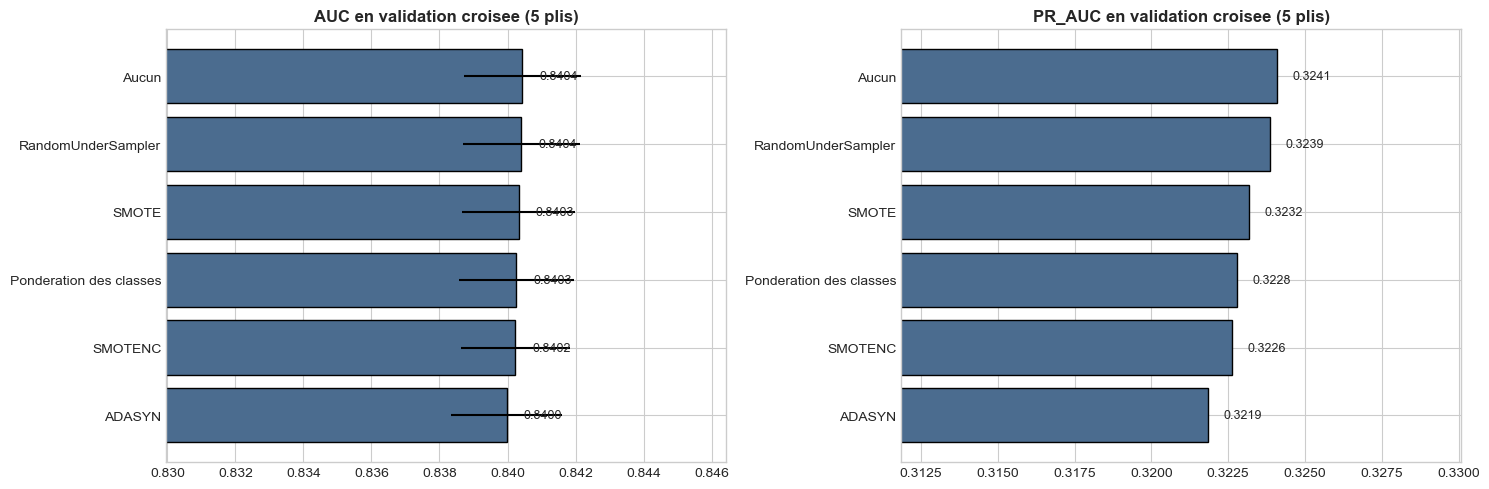

Meilleure methode (AUC moyenne) : Aucun {}
Ecart entre la meilleure et la moins bonne : 0.0005


In [13]:
# ============================================================
# 5.2 VISUALISATION ET CHOIX
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col, err in [(axes[0], 'AUC', 'AUC_std'), (axes[1], 'PR_AUC', None)]:
    d = sampling_df.sort_values(col)
    ax.barh(d['Methode'], d[col], xerr=d[err] if err else None, color='#4b6c8f', edgecolor='black')
    lo = d[col].min()
    ax.set_xlim(lo - 0.01, d[col].max() + 0.006)
    for yv, v in enumerate(d[col]):
        ax.text(v + 0.0005, yv, f'{v:.4f}', va='center', fontsize=9)
    ax.set_title(f'{col} en validation croisee (5 plis)', fontweight='bold')
plt.tight_layout()
plt.savefig('sampling_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

best_sampling = sampling_df.loc[0, 'Methode']
print('Meilleure methode (AUC moyenne) :', best_sampling, sampling_best[best_sampling])
print('Ecart entre la meilleure et la moins bonne :',
      round(sampling_df['AUC'].max() - sampling_df['AUC'].min(), 4))

# Objet de reequilibrage propose ensuite a chaque modele (en plus de "aucun")
if best_sampling in ('Aucun', 'Ponderation des classes'):
    sampler_candidates = lambda cols: ['passthrough']
else:
    params = {k.replace('sampler__', ''): v for k, v in sampling_best[best_sampling].items()}
    makers = {'RandomUnderSampler': lambda cols: RandomUnderSampler(random_state=SEED, **params),
              'SMOTE': lambda cols: SMOTE(random_state=SEED, **params),
              'SMOTENC': lambda cols: smotenc_for(cols, **params),
              'ADASYN': lambda cols: ADASYN(random_state=SEED, **params)}
    sampler_candidates = lambda cols: ['passthrough', makers[best_sampling](cols)]

**Lecture.** Une fois chaque méthode réglée, toutes donnent la **même AUC à 0,0005 près** (0,840), et l'absence de rééquilibrage est même légèrement devant. L'AUC mesure la capacité à classer les clients, et le rééquilibrage ne change presque pas cet ordre.

Ce qui compte vraiment avec 12 % d'intéressés, c'est le **seuil de décision**. Il est réglé plus loin pour chaque modèle. La première version tirait des conclusions de différences entre méthodes qui étaient en fait du bruit.

---
## 6. Sélection des variables : une méthode adaptée à chaque modèle

**Étape commune (filtres)** : deux tests rapides sur toutes les variables.
- **F-test ANOVA** avec correction de Bonferroni (on teste plusieurs variables à la fois)
- **Information mutuelle**, comparée à une **variable sonde** de bruit pur : une variable qui n'apporte pas plus d'information que du bruit est inutile

Une variable rejetée par les **deux** filtres est retirée pour tous les modèles.

**Étape propre à chaque modèle** :

| Modèle | Méthode | Pourquoi elle est adaptée |
|---|---|---|
| Régression logistique | **Stepwise forward** (ajout pas à pas, AUC en validation croisée) | la méthode classique des modèles linéaires, sensible aux variables redondantes |
| Arbre de décision | **RFECV** avec l'importance des nœuds de l'arbre | retire une à une les variables les moins utilisées par l'arbre, le nombre final est choisi par validation croisée |
| Forêt aléatoire | **RFECV** avec l'importance moyenne de la forêt | même principe, avec une importance plus stable (moyenne sur les arbres) |
| Gradient Boosting | **Importance par permutation** sur un jeu de validation | le modèle n'a pas d'importance interne fiable ; on mesure la perte d'AUC quand on mélange une variable |

Pour garder un temps de calcul raisonnable, la sélection se fait sur un **échantillon stratifié de 60 000 clients du train**.

Information mutuelle de la sonde (bruit) : 0.00141
                          F_Score  P_Value       MI  F-test  MI > sonde
Damage_NoInsurance     9521.95307  0.00000  0.08410    True        True
Vehicle_Damage_Yes     8050.39364  0.00000  0.07506    True        True
Previously_Insured     7154.39374  0.00000  0.07405    True        True
Policy_Sales_Channel   3563.75003  0.00000  0.02939    True        True
Age                     720.43182  0.00000  0.02554    True        True
Vehicle_Age_< 1 Year   2509.91767  0.00000  0.02248    True        True
Age_Group              1004.36967  0.00000  0.02087    True        True
Vehicle_Age_1-2 Year   1501.36901  0.00000  0.01284    True        True
Premium_per_Age         370.18643  0.00000  0.01113    True        True
Region_Code             838.91850  0.00000  0.00761    True        True
Vehicle_Age_> 2 Years   693.71139  0.00000  0.00440    True        True
Log_Premium               0.01205  0.91259  0.00415   False        True
Annual_Premiu

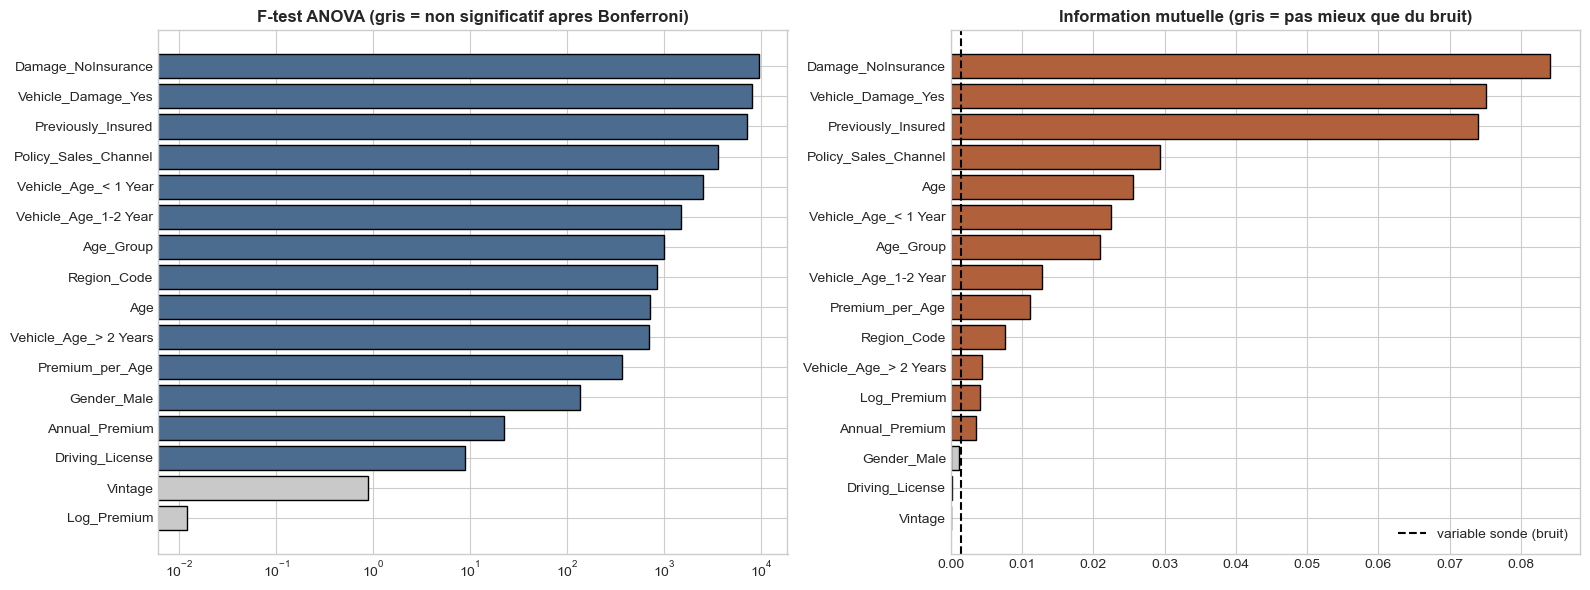

In [14]:
# ============================================================
# 6.1 FILTRES COMMUNS : F-TEST (BONFERRONI) ET INFORMATION MUTUELLE (SONDE)
# ============================================================
def stratified_sample(X, y, n):
    # Echantillon stratifie reproductible (tout le jeu s'il est plus petit que n)
    if n >= len(y):
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=SEED)
    return Xs, ys


X_sel, y_sel = stratified_sample(X_train_enc, y_train, 60000)

f_scores, p_values = f_classif(X_sel, y_sel)
alpha_bonf = 0.05 / len(features_all)

rng = np.random.RandomState(SEED)
X_probe = X_sel.copy()
X_probe['SONDE_bruit'] = rng.normal(size=len(X_probe))
mi = mutual_info_classif(X_probe, y_sel, random_state=SEED,
                         discrete_features=[c in binary_like for c in X_probe.columns])
mi = pd.Series(mi, index=X_probe.columns)
mi_noise = mi['SONDE_bruit']

filters_df = pd.DataFrame({'F_Score': f_scores, 'P_Value': p_values,
                           'MI': mi[features_all].values}, index=features_all)
filters_df['F-test'] = filters_df['P_Value'] < alpha_bonf
filters_df['MI > sonde'] = filters_df['MI'] > mi_noise
filters_df = filters_df.sort_values('MI', ascending=False)
print('Information mutuelle de la sonde (bruit) :', round(mi_noise, 5))
print(filters_df.round(5).to_string())

features_kept = [f for f in features_all if filters_df.loc[f, 'F-test'] or filters_df.loc[f, 'MI > sonde']]
print('\nRetirees par les deux filtres :', [f for f in features_all if f not in features_kept])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
d = filters_df.sort_values('F_Score')
axes[0].barh(d.index, d['F_Score'], color=np.where(d['F-test'], '#4b6c8f', '#c9c9c9'), edgecolor='black')
axes[0].set_xscale('log')
axes[0].set_title('F-test ANOVA (gris = non significatif apres Bonferroni)', fontweight='bold')
d = filters_df.sort_values('MI')
axes[1].barh(d.index, d['MI'], color=np.where(d['MI > sonde'], '#b0613c', '#c9c9c9'), edgecolor='black')
axes[1].axvline(mi_noise, color='black', linestyle='--', label='variable sonde (bruit)')
axes[1].set_title('Information mutuelle (gris = pas mieux que du bruit)', fontweight='bold')
axes[1].legend()
plt.tight_layout()
plt.savefig('filter_methods_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ============================================================
# 6.2 REGRESSION LOGISTIQUE : STEPWISE FORWARD
# ============================================================
lr_pipe_sel = SkPipeline([('scale', StandardScaler().set_output(transform='pandas')), ('lr', LogisticRegression(max_iter=2000))])
sfs = SequentialFeatureSelector(lr_pipe_sel, n_features_to_select='auto', tol=0.001, direction='forward',
                                scoring='roc_auc', cv=CV3, n_jobs=-1)
sfs.fit(X_sel[features_kept], y_sel)
features_lr = [str(c) for c in np.array(features_kept)[sfs.get_support()]]
print('Variables retenues pour la regression logistique (', len(features_lr), ') :')
print(features_lr)

Variables retenues pour la regression logistique ( 6 ) :
['Vehicle_Age_< 1 Year', 'Region_Code', 'Policy_Sales_Channel', 'Age', 'Previously_Insured', 'Damage_NoInsurance']


Decision Tree : 12 variables retenues -> ['Gender_Male', 'Vehicle_Age_1-2 Year', 'Vehicle_Age_> 2 Years', 'Region_Code', 'Policy_Sales_Channel', 'Age', 'Previously_Insured', 'Annual_Premium', 'Damage_NoInsurance', 'Premium_per_Age', 'Log_Premium', 'Age_Group']


Random Forest : 14 variables retenues -> ['Gender_Male', 'Vehicle_Age_1-2 Year', 'Vehicle_Age_< 1 Year', 'Vehicle_Age_> 2 Years', 'Vehicle_Damage_Yes', 'Region_Code', 'Policy_Sales_Channel', 'Age', 'Previously_Insured', 'Annual_Premium', 'Damage_NoInsurance', 'Premium_per_Age', 'Log_Premium', 'Age_Group']


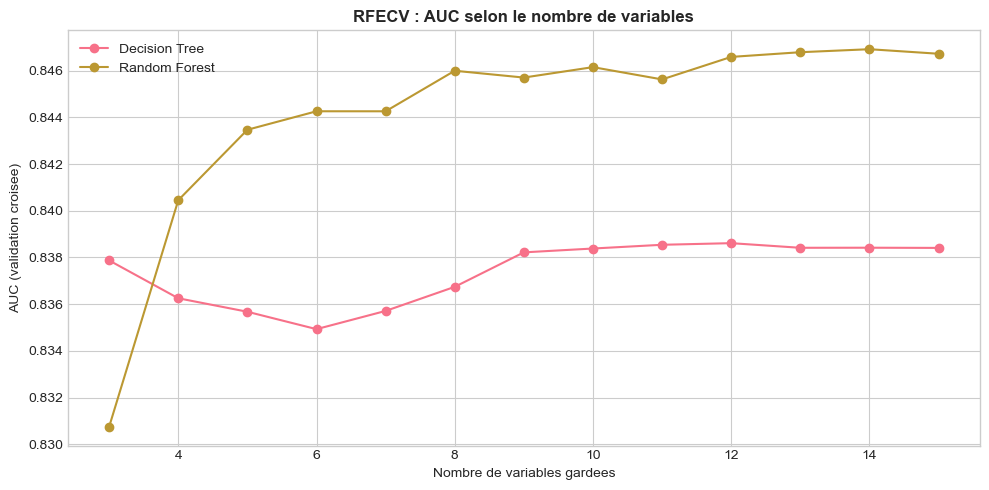

In [16]:
# ============================================================
# 6.3 ARBRE DE DECISION ET FORET ALEATOIRE : RFECV
# ============================================================
rfecv_results = {}
for name, est in [('Decision Tree', DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEED)),
                  ('Random Forest', RandomForestClassifier(n_estimators=150, max_depth=12, min_samples_leaf=50,
                                                           random_state=SEED, n_jobs=-1))]:
    rfecv = RFECV(est, step=1, cv=CV3, scoring='roc_auc', min_features_to_select=3, n_jobs=1)
    rfecv.fit(X_sel[features_kept], y_sel)
    rfecv_results[name] = rfecv
    chosen = [str(c) for c in np.array(features_kept)[rfecv.support_]]
    print(f'{name} : {len(chosen)} variables retenues -> {chosen}')

features_dt = [str(c) for c in np.array(features_kept)[rfecv_results['Decision Tree'].support_]]
features_rf = [str(c) for c in np.array(features_kept)[rfecv_results['Random Forest'].support_]]

fig, ax = plt.subplots(figsize=(10, 5))
for name, rfecv in rfecv_results.items():
    n = np.arange(rfecv.min_features_to_select, len(features_kept) + 1)
    ax.plot(n, rfecv.cv_results_['mean_test_score'], marker='o', label=name)
ax.set_xlabel('Nombre de variables gardees')
ax.set_ylabel('AUC (validation croisee)')
ax.set_title('RFECV : AUC selon le nombre de variables', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig('rfecv_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# ============================================================
# 6.4 GRADIENT BOOSTING : IMPORTANCE PAR PERMUTATION
# ============================================================
X_fit, X_val, y_fit, y_val = train_test_split(X_sel[features_kept], y_sel, test_size=0.3,
                                              stratify=y_sel, random_state=SEED)
hgb_sel = HistGradientBoostingClassifier(random_state=SEED).fit(X_fit, y_fit)
perm = permutation_importance(hgb_sel, X_val, y_val, scoring='roc_auc', n_repeats=10,
                              random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({'Importance': perm.importances_mean, 'Ecart_type': perm.importances_std},
                       index=features_kept).sort_values('Importance', ascending=False)
# On garde une variable si sa perte d'AUC est nettement positive (moyenne - 2 ecarts-types > 0)
perm_df['Gardee'] = perm_df['Importance'] - 2 * perm_df['Ecart_type'] > 0
features_gb = [str(f) for f in features_kept if perm_df.loc[f, 'Gardee']]
print(perm_df.round(5).to_string())
print('\nVariables retenues pour le Gradient Boosting (', len(features_gb), ') :', features_gb)

                       Importance  Ecart_type  Gardee
Previously_Insured        0.11931     0.00408    True
Damage_NoInsurance        0.04782     0.00307    True
Age                       0.02985     0.00228    True
Policy_Sales_Channel      0.01586     0.00151    True
Vehicle_Damage_Yes        0.01444     0.00220    True
Premium_per_Age           0.00540     0.00130    True
Region_Code               0.00496     0.00127    True
Annual_Premium            0.00228     0.00094    True
Vehicle_Age_1-2 Year      0.00154     0.00062    True
Vehicle_Age_< 1 Year      0.00086     0.00057   False
Vehicle_Age_> 2 Years     0.00068     0.00029    True
Gender_Male               0.00048     0.00043   False
Driving_License           0.00020     0.00017   False
Log_Premium               0.00000     0.00000   False
Age_Group                 0.00000     0.00000   False

Variables retenues pour le Gradient Boosting ( 10 ) : ['Vehicle_Age_1-2 Year', 'Vehicle_Age_> 2 Years', 'Vehicle_Damage_Yes', 'Region_C

In [18]:
# ============================================================
# 6.5 SYNTHESE : VARIABLES RETENUES PAR MODELE
# ============================================================
features_by_model = {'Logistic Regression': features_lr, 'Decision Tree': features_dt,
                     'Random Forest': features_rf, 'Gradient Boosting': features_gb}
selection_table = pd.DataFrame({m: ['x' if f in cols else '' for f in features_all]
                                for m, cols in features_by_model.items()}, index=features_all)
selection_table['Filtres'] = ['x' if f in features_kept else '' for f in features_all]
print(selection_table.to_string())
print('\nNombre de variables :', {m: len(c) for m, c in features_by_model.items()})

                      Logistic Regression Decision Tree Random Forest Gradient Boosting Filtres
Gender_Male                                           x             x                         x
Vehicle_Age_1-2 Year                                  x             x                 x       x
Vehicle_Age_< 1 Year                    x                           x                         x
Vehicle_Age_> 2 Years                                 x             x                 x       x
Vehicle_Damage_Yes                                                  x                 x       x
Region_Code                             x             x             x                 x       x
Policy_Sales_Channel                    x             x             x                 x       x
Age                                     x             x             x                 x       x
Driving_License                                                                               x
Previously_Insured                      

**Lecture.** Les méthodes adaptées à chaque modèle ne retiennent pas les mêmes variables :
- le **stepwise** de la régression logistique se contente de **6 variables** ;
- les **RFECV** de l'arbre et de la forêt en gardent **12 et 14** ;
- l'**importance par permutation** du Gradient Boosting en garde **10**.

Toutes s'accordent sur le cœur du problème : déjà assuré ou non (`Previously_Insured`), véhicule endommagé sans assurance (`Damage_NoInsurance`), âge et canal de vente. `Vintage` (ancienneté du client) est rejetée par les deux filtres, car elle n'apporte pas plus d'information que du bruit.

---
## 7. Modèles avec les paramètres par défaut (point de départ)

Quatre modèles, avec toutes les variables, sans rééquilibrage et avec les paramètres par défaut. Ils sont évalués en **validation croisée à 5 plis sur le train** : le test reste intact.

Le Gradient Boosting utilise `HistGradientBoostingClassifier`, la version par histogrammes de scikit-learn. Elle donne les mêmes types de modèles que `GradientBoostingClassifier` mais tourne beaucoup plus vite sur 300 000 clients, ce qui permet un vrai réglage des hyperparamètres.

In [19]:
# ============================================================
# 7.1 EVALUATION PAR DEFAUT (validation croisee 5 plis)
# ============================================================
models_default = {
    'Logistic Regression': LogisticRegression(max_iter=2000),
    'Decision Tree': DecisionTreeClassifier(random_state=SEED),
    'Random Forest': RandomForestClassifier(random_state=SEED, n_jobs=4),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=SEED),
}
before_rows = []
for name, model in models_default.items():
    cv_res = cross_validate(make_pipe(model, features_all), X_train_fe, y_train, cv=CV5,
                            scoring={'AUC': 'roc_auc', 'AP': 'average_precision'}, n_jobs=4)
    before_rows.append({'Model': name, 'AUC': cv_res['test_AUC'].mean(), 'AUC_std': cv_res['test_AUC'].std(),
                        'PR_AUC': cv_res['test_AP'].mean()})
    print(f'{name:<20} AUC = {cv_res["test_AUC"].mean():.4f} (+/- {cv_res["test_AUC"].std():.4f}) '
          f'| PR-AUC = {cv_res["test_AP"].mean():.4f}')
before_df = pd.DataFrame(before_rows).set_index('Model')

Logistic Regression  AUC = 0.8404 (+/- 0.0017) | PR-AUC = 0.3241


Decision Tree        AUC = 0.5998 (+/- 0.0033) | PR-AUC = 0.1730


Random Forest        AUC = 0.8341 (+/- 0.0017) | PR-AUC = 0.3221


Gradient Boosting    AUC = 0.8525 (+/- 0.0019) | PR-AUC = 0.3584


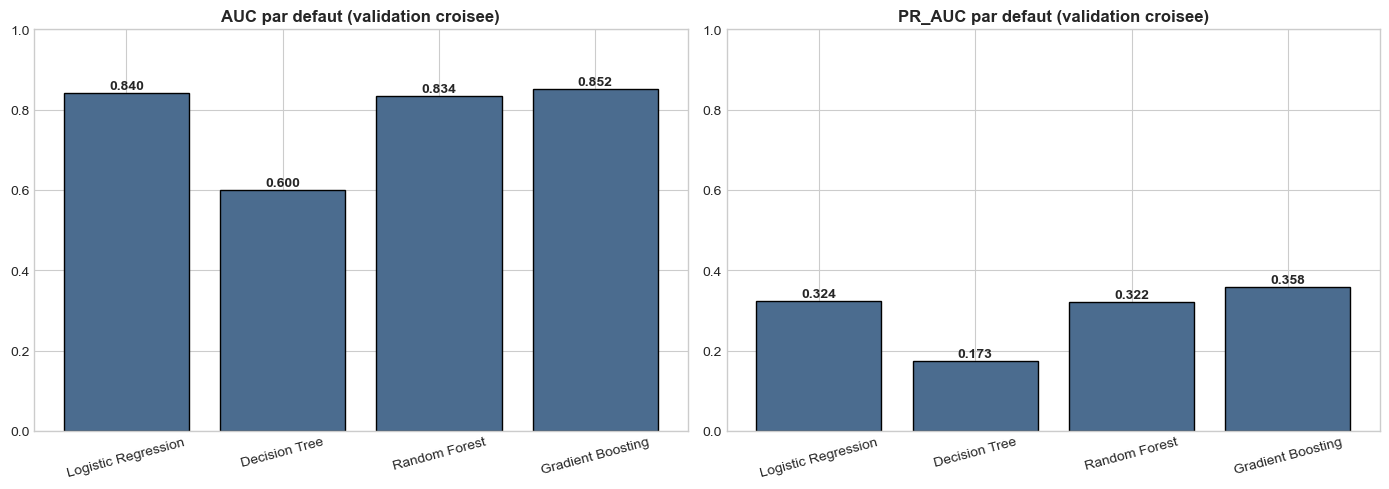

In [20]:
# ============================================================
# 7.2 VISUALISATION AVANT REGLAGE
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ['AUC', 'PR_AUC']):
    bars = ax.bar(before_df.index, before_df[col], color='#4b6c8f', edgecolor='black')
    ax.set_ylim(0, 1)
    ax.set_title(col + ' par defaut (validation croisee)', fontweight='bold')
    ax.tick_params(axis='x', rotation=15)
    for b, v in zip(bars, before_df[col]):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.3f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.savefig('models_before_finetuning.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.3 Visualisation d'un arbre de décision simple

Un arbre de profondeur 3, entraîné sur les variables retenues pour l'arbre et **sans standardisation**, pour lire les règles dans les unités d'origine.

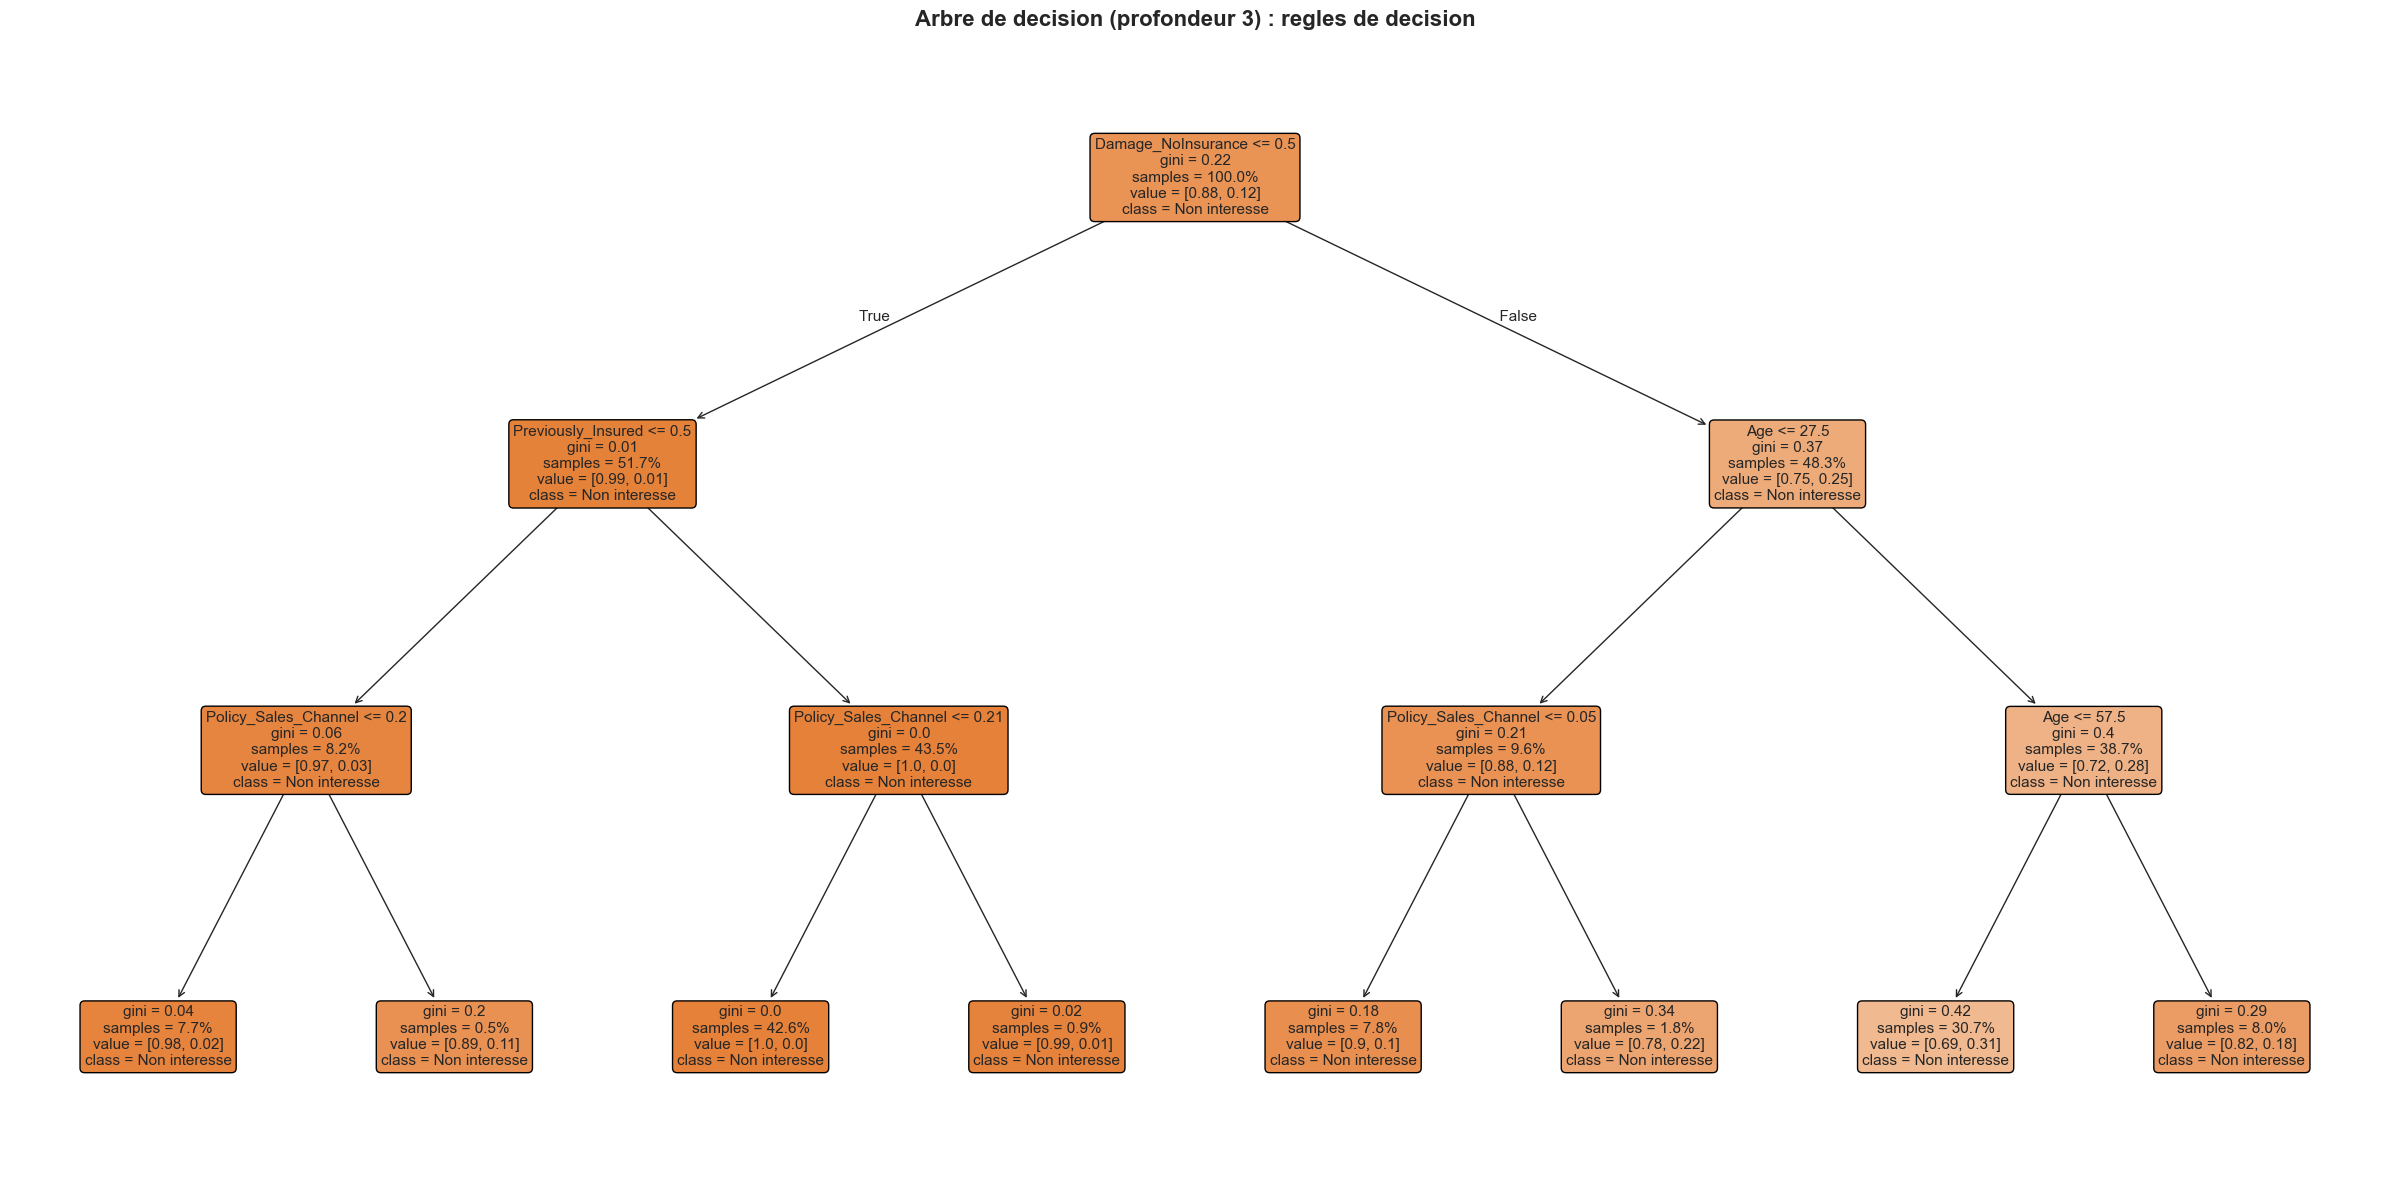

In [21]:
# ============================================================
# 7.3 ARBRE DE DECISION LISIBLE (profondeur 3)
# ============================================================
dt_viz = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, random_state=SEED)
dt_viz.fit(X_train_enc[features_dt], y_train)

plt.figure(figsize=(24, 12))
plot_tree(dt_viz, feature_names=features_dt, class_names=['Non interesse', 'Interesse'],
          filled=True, rounded=True, fontsize=11, proportion=True, precision=2)
plt.title('Arbre de decision (profondeur 3) : regles de decision', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('decision_tree_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.** L'arbre retrouve la règle métier : un client **déjà assuré** n'est presque jamais intéressé, tandis qu'un client **non assuré dont le véhicule a déjà été endommagé** l'est dans environ un cas sur quatre. L'âge et le canal de vente affinent ensuite la décision.

---
## 8. Réglage de chaque modèle

Pour chaque modèle :
1. **Recherche aléatoire d'hyperparamètres** (`RandomizedSearchCV`, graine fixe). La recherche compare aussi les variables choisies pour ce modèle (section 6) avec l'ensemble des variables : la sélection n'est gardée que si elle fait au moins aussi bien. La recherche choisit aussi le traitement du déséquilibre : rien, pondération des classes ou la meilleure méthode de rééquilibrage de la section 5. La recherche se fait sur un échantillon stratifié de 80 000 clients du train, avec une validation croisée à 3 plis.
2. **Réentraînement** du meilleur réglage sur tout le train.
3. **Choix du seuil de décision** : par défaut, un client est déclaré intéressé si sa probabilité dépasse 0,5. Ce seuil n'a aucune raison d'être le bon. On calcule les prédictions **hors échantillon** du train (validation croisée à 5 plis) et on garde le seuil qui maximise le F1.

| Modèle | Hyperparamètres explorés |
|---|---|
| Régression logistique | `C` (force de régularisation), pénalité L1 ou L2, pondération des classes |
| Arbre de décision | profondeur, taille minimale des feuilles et des nœuds, critère (Gini, entropie), part des variables testées, pondération |
| Forêt aléatoire | nombre d'arbres, profondeur, taille des feuilles, part des variables par nœud, part des clients par arbre, pondération |
| Gradient Boosting | taux d'apprentissage, nombre de feuilles, taille des feuilles, régularisation L2, part des variables, pondération ; nombre d'arbres fixé par arrêt précoce |

In [22]:
# ============================================================
# 8.1 ESPACES DE RECHERCHE ET OUTILS
# ============================================================
search_spaces = {
    'Logistic Regression': (LogisticRegression(max_iter=3000, solver='liblinear'), 30, {
        'model__C': loguniform(1e-3, 1e2), 'model__penalty': ['l1', 'l2'],
        'model__class_weight': [None, 'balanced']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED), 40, {
        'model__max_depth': randint(3, 25), 'model__min_samples_leaf': randint(10, 500),
        'model__min_samples_split': randint(2, 200), 'model__criterion': ['gini', 'entropy'],
        'model__max_features': [None, 'sqrt', 0.7], 'model__class_weight': [None, 'balanced']}),
    'Random Forest': (RandomForestClassifier(random_state=SEED, n_jobs=1), 25, {
        'model__n_estimators': [200, 300, 400], 'model__max_depth': [8, 12, 16, 20, None],
        'model__min_samples_leaf': [5, 10, 20, 50, 100], 'model__max_features': ['sqrt', 0.5, 0.8],
        'model__max_samples': [0.5, 0.8, None], 'model__class_weight': [None, 'balanced_subsample']}),
    'Gradient Boosting': (HistGradientBoostingClassifier(random_state=SEED, max_iter=1000, early_stopping=True,
                                                         n_iter_no_change=30, validation_fraction=0.1), 40, {
        'model__learning_rate': loguniform(0.02, 0.3), 'model__max_leaf_nodes': randint(15, 128),
        'model__min_samples_leaf': randint(20, 400), 'model__l2_regularization': loguniform(1e-3, 10),
        'model__max_features': [1.0, 0.8, 0.5], 'model__class_weight': [None, 'balanced']}),
}

X_tune, y_tune = stratified_sample(X_train_fe, y_train, 80000)


def oof_threshold(pipe):
    # Predictions hors echantillon du train (5 plis) -> AUC par pli et seuil qui maximise le F1
    oof = np.zeros(len(y_train))
    fold_auc = []
    for tr, va in CV5.split(X_train_fe, y_train):
        m = clone(pipe).fit(X_train_fe.iloc[tr], y_train.iloc[tr])
        oof[va] = m.predict_proba(X_train_fe.iloc[va])[:, 1]
        fold_auc.append(roc_auc_score(y_train.iloc[va], oof[va]))
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    return oof, np.array(fold_auc), float(thr[np.argmax(f1)])


def test_metrics(name, prob, thr):
    pred = (prob >= thr).astype(int)
    return {'Model': name, 'Seuil': thr, 'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred), 'Recall': recall_score(y_test, pred),
            'F1_Score': f1_score(y_test, pred), 'ROC_AUC': roc_auc_score(y_test, prob),
            'PR_AUC': average_precision_score(y_test, prob)}


tuned, results_after, results_default_threshold, probabilities, cv_fold_auc = {}, [], [], {}, {}

In [23]:
# ============================================================
# 8.2 REGLAGE : LOGISTIC REGRESSION
# ============================================================
name = 'Logistic Regression'
model, n_iter, space = search_spaces[name]
cols = features_by_model[name]
space = dict(space, sampler=sampler_candidates(cols))
# La selection n'est gardee que si elle fait au moins aussi bien que toutes les variables
if best_sampling != 'SMOTENC':
    space['select__transformers'] = [[('keep', 'passthrough', cols)], [('keep', 'passthrough', features_all)]]

search = RandomizedSearchCV(make_pipe(model, cols), space, n_iter=n_iter, cv=CV3, scoring='roc_auc',
                            random_state=SEED, n_jobs=-1, error_score='raise')
search.fit(X_tune, y_tune)
chosen_cols = search.best_params_.get('select__transformers', [('keep', 'passthrough', cols)])[0][2]
features_by_model[name] = list(chosen_cols)
best_params = {k: (type(v).__name__ if k == 'sampler' and v != 'passthrough' else v)
               for k, v in search.best_params_.items() if k != 'select__transformers'}
print('Variables retenues :', 'selection propre au modele' if len(chosen_cols) < len(features_all) else 'toutes',
      f'({len(chosen_cols)})')
print('Meilleurs parametres :', best_params)
print('AUC de la recherche (3 plis, 80 000 clients) :', round(search.best_score_, 4))

best_pipe = clone(search.best_estimator_)
if name == 'Random Forest':
    best_pipe.set_params(model__n_jobs=-1)
oof, fold_auc, thr = oof_threshold(best_pipe)
best_pipe.fit(X_train_fe, y_train)
prob = best_pipe.predict_proba(X_test_fe)[:, 1]

tuned[name] = best_pipe
probabilities[name] = prob
cv_fold_auc[name] = fold_auc
results_after.append(test_metrics(name, prob, thr))
results_default_threshold.append(test_metrics(name, prob, 0.5))
print(f'AUC hors echantillon (5 plis) : {fold_auc.mean():.4f} (+/- {fold_auc.std():.4f})')
print(f'Seuil optimal (F1, train) : {thr:.3f}')
print(pd.DataFrame([results_default_threshold[-1], results_after[-1]],
                   index=['seuil 0,5', 'seuil optimal']).drop(columns='Model').round(4).to_string())

Variables retenues : toutes (16)
Meilleurs parametres : {'model__C': np.float64(0.8585306974480479), 'model__class_weight': None, 'model__penalty': 'l2', 'sampler': 'passthrough'}
AUC de la recherche (3 plis, 80 000 clients) : 0.8372


AUC hors echantillon (5 plis) : 0.8405 (+/- 0.0017)
Seuil optimal (F1, train) : 0.204
               Seuil  Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
seuil 0,5      0.500    0.8774     0.2857  0.0004    0.0009   0.8432  0.3291
seuil optimal  0.204    0.7522     0.3050  0.7990    0.4415   0.8432  0.3291


In [24]:
# ============================================================
# 8.3 REGLAGE : DECISION TREE
# ============================================================
name = 'Decision Tree'
model, n_iter, space = search_spaces[name]
cols = features_by_model[name]
space = dict(space, sampler=sampler_candidates(cols))
# La selection n'est gardee que si elle fait au moins aussi bien que toutes les variables
if best_sampling != 'SMOTENC':
    space['select__transformers'] = [[('keep', 'passthrough', cols)], [('keep', 'passthrough', features_all)]]

search = RandomizedSearchCV(make_pipe(model, cols), space, n_iter=n_iter, cv=CV3, scoring='roc_auc',
                            random_state=SEED, n_jobs=-1, error_score='raise')
search.fit(X_tune, y_tune)
chosen_cols = search.best_params_.get('select__transformers', [('keep', 'passthrough', cols)])[0][2]
features_by_model[name] = list(chosen_cols)
best_params = {k: (type(v).__name__ if k == 'sampler' and v != 'passthrough' else v)
               for k, v in search.best_params_.items() if k != 'select__transformers'}
print('Variables retenues :', 'selection propre au modele' if len(chosen_cols) < len(features_all) else 'toutes',
      f'({len(chosen_cols)})')
print('Meilleurs parametres :', best_params)
print('AUC de la recherche (3 plis, 80 000 clients) :', round(search.best_score_, 4))

best_pipe = clone(search.best_estimator_)
if name == 'Random Forest':
    best_pipe.set_params(model__n_jobs=-1)
oof, fold_auc, thr = oof_threshold(best_pipe)
best_pipe.fit(X_train_fe, y_train)
prob = best_pipe.predict_proba(X_test_fe)[:, 1]

tuned[name] = best_pipe
probabilities[name] = prob
cv_fold_auc[name] = fold_auc
results_after.append(test_metrics(name, prob, thr))
results_default_threshold.append(test_metrics(name, prob, 0.5))
print(f'AUC hors echantillon (5 plis) : {fold_auc.mean():.4f} (+/- {fold_auc.std():.4f})')
print(f'Seuil optimal (F1, train) : {thr:.3f}')
print(pd.DataFrame([results_default_threshold[-1], results_after[-1]],
                   index=['seuil 0,5', 'seuil optimal']).drop(columns='Model').round(4).to_string())

Variables retenues : selection propre au modele (12)
Meilleurs parametres : {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 17, 'model__max_features': 0.7, 'model__min_samples_leaf': 437, 'model__min_samples_split': 9, 'sampler': 'passthrough'}
AUC de la recherche (3 plis, 80 000 clients) : 0.8413


AUC hors echantillon (5 plis) : 0.8482 (+/- 0.0020)
Seuil optimal (F1, train) : 0.668
                Seuil  Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
seuil 0,5      0.5000    0.6969     0.2784  0.9253     0.428   0.8488  0.3481
seuil optimal  0.6681    0.7688     0.3167  0.7656     0.448   0.8488  0.3481


In [25]:
# ============================================================
# 8.4 REGLAGE : RANDOM FOREST
# ============================================================
name = 'Random Forest'
model, n_iter, space = search_spaces[name]
cols = features_by_model[name]
space = dict(space, sampler=sampler_candidates(cols))
# La selection n'est gardee que si elle fait au moins aussi bien que toutes les variables
if best_sampling != 'SMOTENC':
    space['select__transformers'] = [[('keep', 'passthrough', cols)], [('keep', 'passthrough', features_all)]]

search = RandomizedSearchCV(make_pipe(model, cols), space, n_iter=n_iter, cv=CV3, scoring='roc_auc',
                            random_state=SEED, n_jobs=-1, error_score='raise')
search.fit(X_tune, y_tune)
chosen_cols = search.best_params_.get('select__transformers', [('keep', 'passthrough', cols)])[0][2]
features_by_model[name] = list(chosen_cols)
best_params = {k: (type(v).__name__ if k == 'sampler' and v != 'passthrough' else v)
               for k, v in search.best_params_.items() if k != 'select__transformers'}
print('Variables retenues :', 'selection propre au modele' if len(chosen_cols) < len(features_all) else 'toutes',
      f'({len(chosen_cols)})')
print('Meilleurs parametres :', best_params)
print('AUC de la recherche (3 plis, 80 000 clients) :', round(search.best_score_, 4))

best_pipe = clone(search.best_estimator_)
if name == 'Random Forest':
    best_pipe.set_params(model__n_jobs=-1)
oof, fold_auc, thr = oof_threshold(best_pipe)
best_pipe.fit(X_train_fe, y_train)
prob = best_pipe.predict_proba(X_test_fe)[:, 1]

tuned[name] = best_pipe
probabilities[name] = prob
cv_fold_auc[name] = fold_auc
results_after.append(test_metrics(name, prob, thr))
results_default_threshold.append(test_metrics(name, prob, 0.5))
print(f'AUC hors echantillon (5 plis) : {fold_auc.mean():.4f} (+/- {fold_auc.std():.4f})')
print(f'Seuil optimal (F1, train) : {thr:.3f}')
print(pd.DataFrame([results_default_threshold[-1], results_after[-1]],
                   index=['seuil 0,5', 'seuil optimal']).drop(columns='Model').round(4).to_string())

Variables retenues : selection propre au modele (14)
Meilleurs parametres : {'sampler': 'passthrough', 'model__n_estimators': 300, 'model__min_samples_leaf': 50, 'model__max_samples': 0.8, 'model__max_features': 'sqrt', 'model__max_depth': 20, 'model__class_weight': None}
AUC de la recherche (3 plis, 80 000 clients) : 0.8462


AUC hors echantillon (5 plis) : 0.8517 (+/- 0.0015)
Seuil optimal (F1, train) : 0.221
                Seuil  Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
seuil 0,5      0.5000    0.8775     0.5362  0.0040    0.0079   0.8518  0.3575
seuil optimal  0.2209    0.7693     0.3191  0.7783    0.4526   0.8518  0.3575


In [26]:
# ============================================================
# 8.5 REGLAGE : GRADIENT BOOSTING
# ============================================================
name = 'Gradient Boosting'
model, n_iter, space = search_spaces[name]
cols = features_by_model[name]
space = dict(space, sampler=sampler_candidates(cols))
# La selection n'est gardee que si elle fait au moins aussi bien que toutes les variables
if best_sampling != 'SMOTENC':
    space['select__transformers'] = [[('keep', 'passthrough', cols)], [('keep', 'passthrough', features_all)]]

search = RandomizedSearchCV(make_pipe(model, cols), space, n_iter=n_iter, cv=CV3, scoring='roc_auc',
                            random_state=SEED, n_jobs=-1, error_score='raise')
search.fit(X_tune, y_tune)
chosen_cols = search.best_params_.get('select__transformers', [('keep', 'passthrough', cols)])[0][2]
features_by_model[name] = list(chosen_cols)
best_params = {k: (type(v).__name__ if k == 'sampler' and v != 'passthrough' else v)
               for k, v in search.best_params_.items() if k != 'select__transformers'}
print('Variables retenues :', 'selection propre au modele' if len(chosen_cols) < len(features_all) else 'toutes',
      f'({len(chosen_cols)})')
print('Meilleurs parametres :', best_params)
print('AUC de la recherche (3 plis, 80 000 clients) :', round(search.best_score_, 4))

best_pipe = clone(search.best_estimator_)
if name == 'Random Forest':
    best_pipe.set_params(model__n_jobs=-1)
oof, fold_auc, thr = oof_threshold(best_pipe)
best_pipe.fit(X_train_fe, y_train)
prob = best_pipe.predict_proba(X_test_fe)[:, 1]

tuned[name] = best_pipe
probabilities[name] = prob
cv_fold_auc[name] = fold_auc
results_after.append(test_metrics(name, prob, thr))
results_default_threshold.append(test_metrics(name, prob, 0.5))
print(f'AUC hors echantillon (5 plis) : {fold_auc.mean():.4f} (+/- {fold_auc.std():.4f})')
print(f'Seuil optimal (F1, train) : {thr:.3f}')
print(pd.DataFrame([results_default_threshold[-1], results_after[-1]],
                   index=['seuil 0,5', 'seuil optimal']).drop(columns='Model').round(4).to_string())

Variables retenues : toutes (16)
Meilleurs parametres : {'model__class_weight': None, 'model__l2_regularization': np.float64(4.337920697490942), 'model__learning_rate': np.float64(0.04030685101059539), 'model__max_features': 0.8, 'model__max_leaf_nodes': 20, 'model__min_samples_leaf': 73, 'sampler': 'passthrough'}
AUC de la recherche (3 plis, 80 000 clients) : 0.8461


AUC hors echantillon (5 plis) : 0.8531 (+/- 0.0016)
Seuil optimal (F1, train) : 0.223
                Seuil  Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
seuil 0,5      0.5000    0.8774     0.4898  0.0026    0.0051   0.8535  0.3601
seuil optimal  0.2228    0.7722     0.3213  0.7720    0.4537   0.8535  0.3601


                     AUC par defaut (CV)  AUC apres reglage (CV)  Gain AUC  F1 test, seuil 0,5  F1 test, seuil optimal
Logistic Regression               0.8404                  0.8405    0.0000              0.0009                  0.4415
Decision Tree                     0.5998                  0.8482    0.2483              0.4280                  0.4480
Random Forest                     0.8341                  0.8517    0.0177              0.0079                  0.4526
Gradient Boosting                 0.8525                  0.8531    0.0006              0.0051                  0.4537


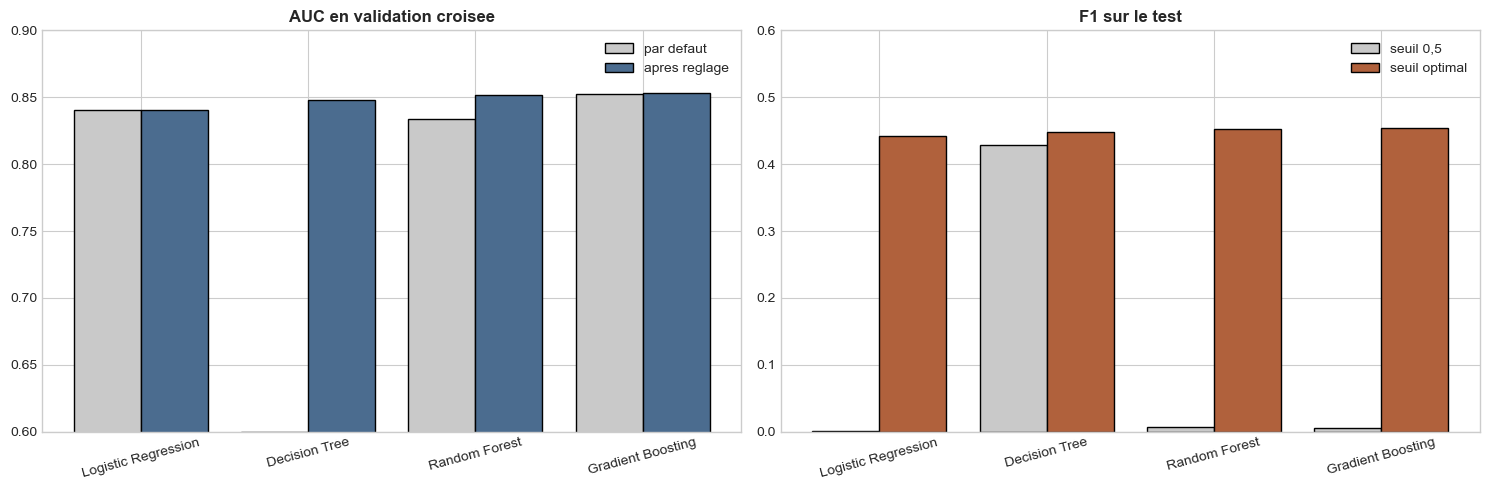

In [27]:
# ============================================================
# 8.6 AVANT / APRES REGLAGE
# ============================================================
after_df = pd.DataFrame(results_after).set_index('Model')
default_thr_df = pd.DataFrame(results_default_threshold).set_index('Model')
gain_df = pd.DataFrame({
    'AUC par defaut (CV)': before_df['AUC'],
    'AUC apres reglage (CV)': pd.Series({m: a.mean() for m, a in cv_fold_auc.items()}),
})
gain_df['Gain AUC'] = gain_df['AUC apres reglage (CV)'] - gain_df['AUC par defaut (CV)']
gain_df['F1 test, seuil 0,5'] = default_thr_df['F1_Score']
gain_df['F1 test, seuil optimal'] = after_df['F1_Score']
print(gain_df.round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(gain_df))
axes[0].bar(x - 0.2, gain_df['AUC par defaut (CV)'], 0.4, label='par defaut', color='#c9c9c9', edgecolor='black')
axes[0].bar(x + 0.2, gain_df['AUC apres reglage (CV)'], 0.4, label='apres reglage', color='#4b6c8f', edgecolor='black')
axes[0].set_ylim(0.6, 0.9)
axes[0].set_title('AUC en validation croisee', fontweight='bold')
axes[1].bar(x - 0.2, gain_df['F1 test, seuil 0,5'], 0.4, label='seuil 0,5', color='#c9c9c9', edgecolor='black')
axes[1].bar(x + 0.2, gain_df['F1 test, seuil optimal'], 0.4, label='seuil optimal', color='#b0613c', edgecolor='black')
axes[1].set_ylim(0, 0.6)
axes[1].set_title('F1 sur le test', fontweight='bold')
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(gain_df.index, rotation=15)
    ax.legend()
plt.tight_layout()
plt.savefig('finetuning_gain.png', dpi=150, bbox_inches='tight')
plt.show()

**Lecture.**
- **L'arbre de décision** gagne le plus au réglage : son AUC passe de 0,60 à 0,848. Par défaut, il pousse jusqu'à mémoriser les données d'apprentissage ; une fois sa profondeur et la taille de ses feuilles réglées, il généralise.
- **La forêt aléatoire** gagne 0,018 d'AUC. **La régression logistique et le Gradient Boosting** étaient déjà proches de leur meilleure version.
- Pour la régression logistique et le Gradient Boosting, la recherche a gardé **toutes les variables** : la sélection propre au modèle faisait un peu moins bien, elle n'a donc pas été retenue.
- **Le seuil compte plus que le modèle.** Avec le seuil de 0,5, la forêt et le Gradient Boosting ne détectent presque aucun client intéressé (F1 proche de 0). Avec le seuil choisi sur le train, le F1 dépasse 0,45 pour tous les modèles.

---
## 9. Interprétation des modèles

| Technique | Niveau | Ce qu'elle dit |
|---|---|---|
| **Importance par permutation** | globale | perte d'AUC quand on mélange une variable, comparable entre les 4 modèles |
| **SHAP** | globale et locale | contribution de chaque variable à chaque prédiction (valeurs de Shapley) |
| **LIME** | locale | modèle linéaire simple qui imite le modèle autour d'un client |
| **Contrefactuels** | locale | ce qu'il faudrait changer chez un client pour qu'il soit prédit intéressé |

L'interprétation détaillée (SHAP, LIME, contrefactuels) porte sur le **meilleur modèle**, choisi par l'AUC en validation croisée sur le train et non sur le test.

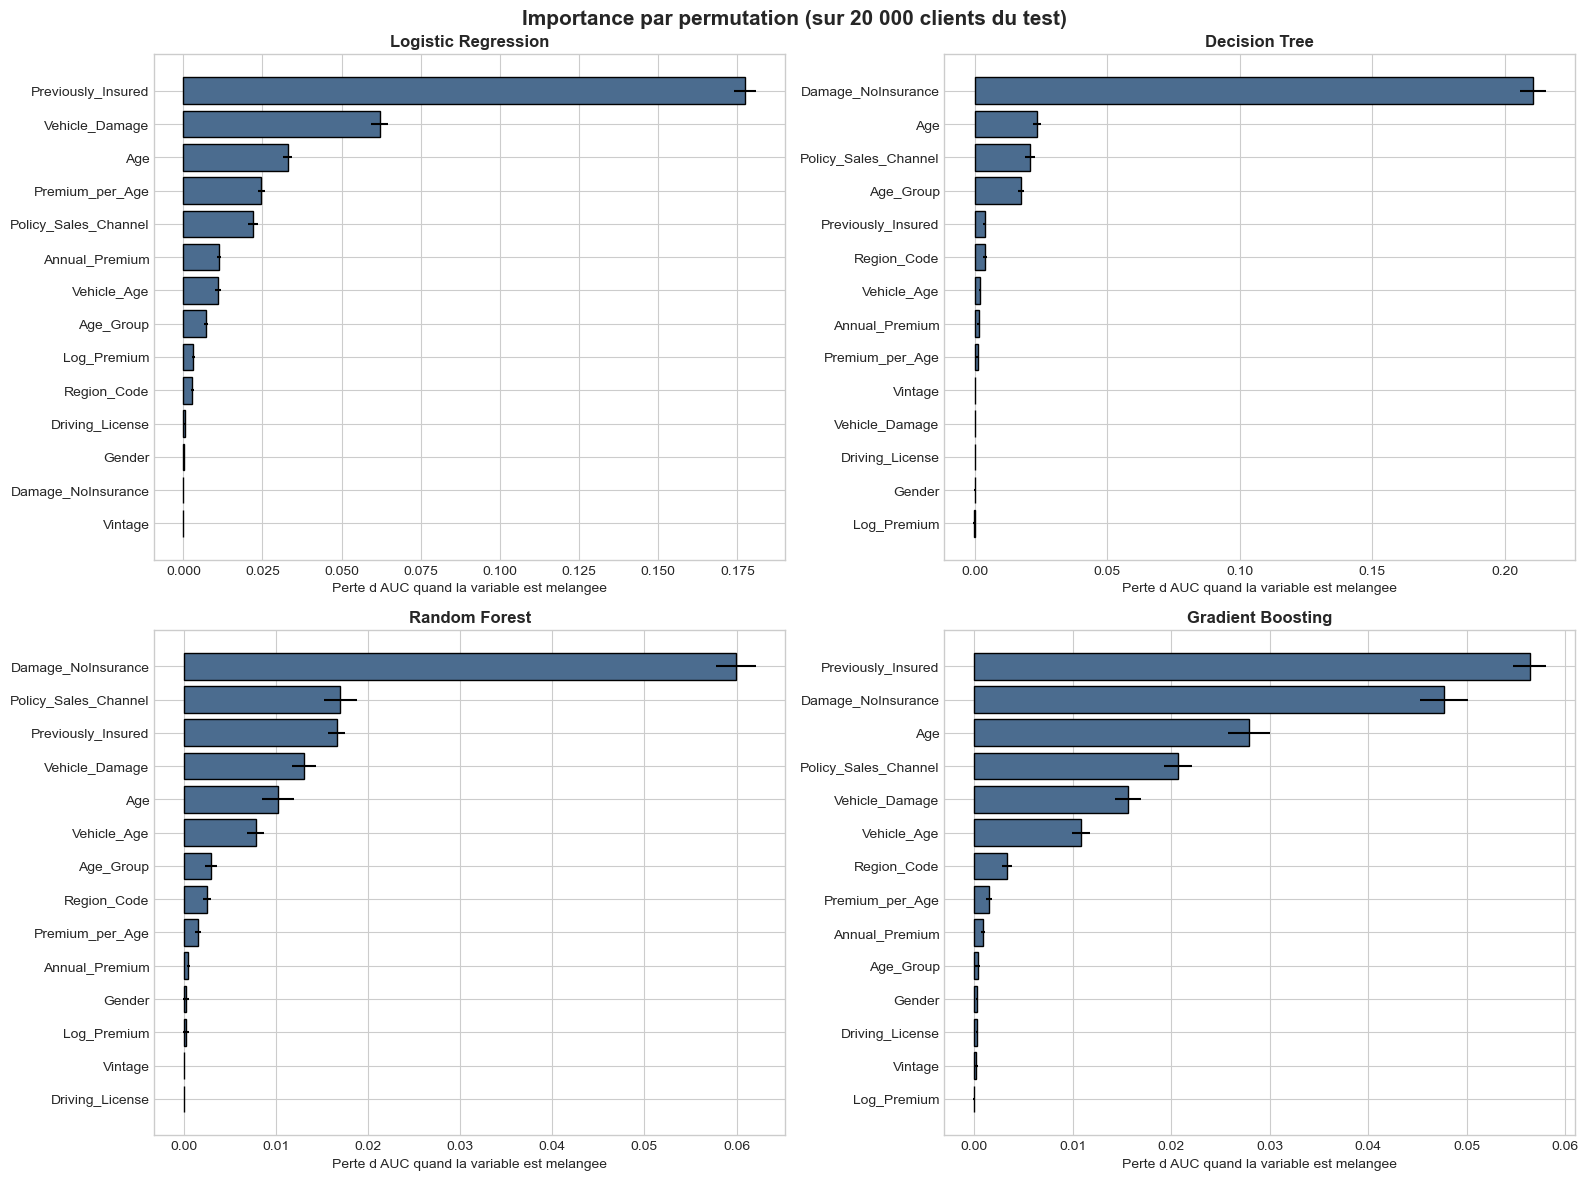

Meilleur modele (AUC en validation croisee) : Gradient Boosting


In [28]:
# ============================================================
# 9.1 IMPORTANCE PAR PERMUTATION (4 modeles, variables d'origine)
# ============================================================
X_imp, y_imp = stratified_sample(X_test_fe, y_test, 20000)
raw_features = [c for c in X_test_fe.columns]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, (name, pipe) in zip(axes.flatten(), tuned.items()):
    pi = permutation_importance(pipe, X_imp, y_imp, scoring='roc_auc', n_repeats=5,
                                random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=raw_features).sort_values()
    ax.barh(imp.index, imp.values, xerr=pd.Series(pi.importances_std, index=raw_features)[imp.index],
            color='#4b6c8f', edgecolor='black')
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Perte d AUC quand la variable est melangee')
plt.suptitle('Importance par permutation (sur 20 000 clients du test)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig('feature_importance_models.png', dpi=150, bbox_inches='tight')
plt.show()

best_name = max(cv_fold_auc, key=lambda m: cv_fold_auc[m].mean())
best_pipe = tuned[best_name]
best_thr = after_df.loc[best_name, 'Seuil']
print('Meilleur modele (AUC en validation croisee) :', best_name)

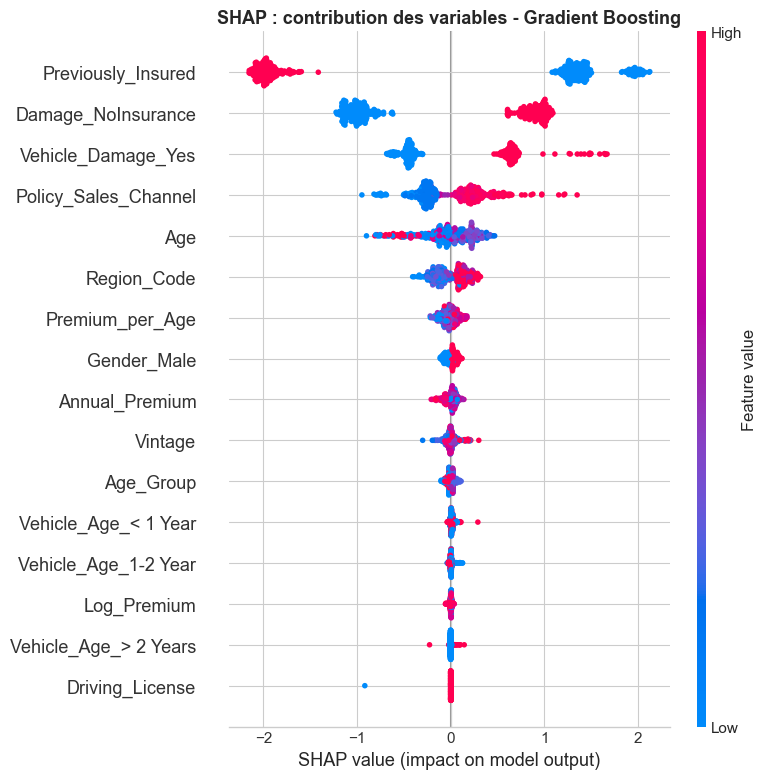

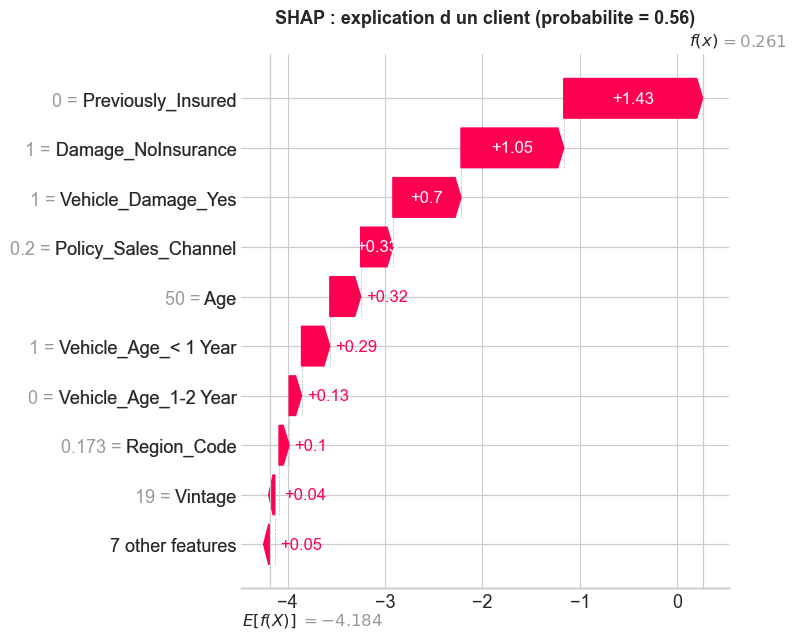

In [29]:
# ============================================================
# 9.2 SHAP (meilleur modele)
# ============================================================
pre = SkPipeline([(n, s) for n, s in best_pipe.steps if n not in ('sampler', 'model')])
final_model = best_pipe.named_steps['model']
Xt_test = pre.transform(X_test_fe)
scaler = best_pipe.named_steps['scale']
Xt_test_raw = pd.DataFrame(scaler.inverse_transform(Xt_test), columns=Xt_test.columns, index=Xt_test.index) \
    if scaler != 'passthrough' else Xt_test

X_shap = Xt_test.sample(500, random_state=SEED)
if isinstance(final_model, LogisticRegression):
    explainer = shap.LinearExplainer(final_model, pre.transform(X_train_fe.sample(2000, random_state=SEED)))
else:
    explainer = shap.TreeExplainer(final_model)
sv = explainer.shap_values(X_shap)
if isinstance(sv, list):
    sv = sv[1]
elif np.ndim(sv) == 3:
    sv = sv[:, :, 1]
base = np.atleast_1d(explainer.expected_value)[-1]

plt.figure()
shap.summary_plot(sv, Xt_test_raw.loc[X_shap.index], show=False)
plt.title('SHAP : contribution des variables - ' + best_name, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# Client explique : le client de l'echantillon avec la probabilite la plus elevee
proba_shap = final_model.predict_proba(X_shap)[:, 1]
k = int(np.argmax(proba_shap))
client_id = X_shap.index[k]
plt.figure()
shap.waterfall_plot(shap.Explanation(values=sv[k], base_values=base,
                                     data=Xt_test_raw.loc[client_id].values,
                                     feature_names=list(X_shap.columns)), show=False)
plt.title(f'SHAP : explication d un client (probabilite = {proba_shap[k]:.2f})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall.png', dpi=150, bbox_inches='tight')
plt.show()

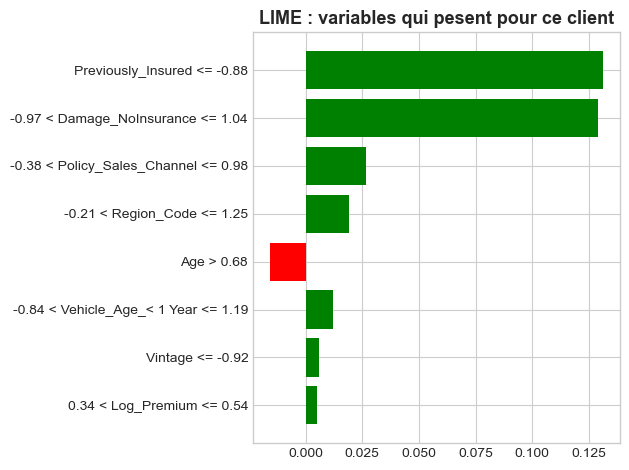

Valeurs reelles de ce client :
Gender                    Female
Age                         50.0
Driving_License              1.0
Region_Code                 28.0
Previously_Insured           0.0
Vehicle_Age             < 1 Year
Vehicle_Damage               Yes
Annual_Premium           32665.0
Policy_Sales_Channel        26.0
Vintage                     19.0


In [30]:
# ============================================================
# 9.3 LIME (meme client)
# ============================================================
Xt_train_sample = pre.transform(X_train_fe.sample(5000, random_state=SEED))
explainer_lime = LimeTabularExplainer(Xt_train_sample.values, feature_names=list(Xt_train_sample.columns),
                                      class_names=['Non interesse', 'Interesse'], mode='classification',
                                      discretize_continuous=True, random_state=SEED)
predict_fn = lambda a: final_model.predict_proba(pd.DataFrame(a, columns=Xt_train_sample.columns))
exp = explainer_lime.explain_instance(Xt_test.loc[client_id].values, predict_fn, num_features=8)
fig = exp.as_pyplot_figure()
plt.title('LIME : variables qui pesent pour ce client', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('lime_explanation.png', dpi=150, bbox_inches='tight')
plt.show()
print('Valeurs reelles de ce client :')
print(X_test_imp.loc[client_id].to_string())

In [31]:
# ============================================================
# 9.4 CONTREFACTUELS : QUE FAUDRAIT-IL CHANGER ?
# ============================================================
# Pour des clients predits non interesses, on change une variable a la fois
# (valeurs realistes observees dans le train) et on regarde si le client passe au-dessus du seuil.
candidates = {
    'Previously_Insured': [0.0, 1.0],
    'Vehicle_Damage': ['Yes', 'No'],
    'Vehicle_Age': ['< 1 Year', '1-2 Year', '> 2 Years'],
    'Policy_Sales_Channel': [float(c) for c in X_train_imp['Policy_Sales_Channel'].value_counts().index[:5]],
    'Age': list(np.percentile(X_train_imp['Age'], [10, 50, 90]).round()),
    'Annual_Premium': list(np.percentile(X_train_imp['Annual_Premium'], [10, 50, 90]).round()),
}
prob_test = probabilities[best_name]
non_interested = X_test_imp.index[prob_test < best_thr][:200]
cf_rows = []
for cid in non_interested:
    base_row = X_test_imp.loc[[cid]]
    p0 = best_pipe.predict_proba(add_features(base_row))[0, 1]
    for feat, values in candidates.items():
        for v in values:
            if base_row[feat].iloc[0] == v:
                continue
            mod = base_row.copy()
            mod[feat] = v
            p1 = best_pipe.predict_proba(add_features(mod))[0, 1]
            if p1 >= best_thr:
                cf_rows.append({'Client': cid, 'Variable': feat, 'Avant': base_row[feat].iloc[0], 'Apres': v,
                                'Proba avant': round(p0, 3), 'Proba apres': round(p1, 3)})
cf_df = pd.DataFrame(cf_rows)
print(f'{len(non_interested)} clients predits non interesses analyses')
if cf_df.empty:
    print('Aucun changement d une seule variable ne suffit a les faire basculer.')
else:
    print('\nClients qui basculent, par variable modifiee :')
    print(cf_df.groupby('Variable')['Client'].nunique().sort_values(ascending=False).to_string())
    print('\nExemples :')
    print(cf_df.sort_values('Proba apres', ascending=False).head(10).to_string(index=False))

200 clients predits non interesses analyses

Clients qui basculent, par variable modifiee :
Variable
Age                     31
Policy_Sales_Channel    24
Vehicle_Age             20
Vehicle_Damage           8
Previously_Insured       5
Annual_Premium           2

Exemples :
 Client           Variable    Avant    Apres  Proba avant  Proba apres
  56593        Vehicle_Age 1-2 Year < 1 Year        0.190        0.446
 379156                Age     75.0     36.0        0.149        0.438
  96679 Previously_Insured      1.0      0.0        0.009        0.424
 222466                Age     24.0     36.0        0.220        0.415
 359813        Vehicle_Age 1-2 Year < 1 Year        0.208        0.415
 170718 Previously_Insured      1.0      0.0        0.010        0.395
 163224 Previously_Insured      1.0      0.0        0.005        0.392
 142645        Vehicle_Age 1-2 Year < 1 Year        0.189        0.382
 247206        Vehicle_Age 1-2 Year < 1 Year        0.204        0.372
   7389        

**Lecture.**
- L'importance par permutation, SHAP et LIME s'accordent : `Previously_Insured` est de loin la variable la plus influente, suivie de l'âge, des dommages au véhicule et du canal de vente.
- Les contrefactuels montrent les leviers qui font basculer un client. Certains ne sont **pas actionnables**, comme le fait d'être déjà assuré ou l'âge.
- Le levier sur lequel l'entreprise peut agir est le **canal de vente** (`Policy_Sales_Channel`) : certains canaux (26 et 124) convertissent nettement mieux. C'est la recommandation la plus utile pour une campagne.

---
## 10. Évaluation finale sur le jeu de test

Le test (76 222 clients) n'a servi à **aucun** choix : ni rééquilibrage, ni variables, ni hyperparamètres, ni seuil. Ces scores mesurent donc honnêtement ce qu'on peut attendre sur de nouveaux clients.

In [32]:
# ============================================================
# 10.1 TABLEAU FINAL (seuil optimal de chaque modele)
# ============================================================
final_df = after_df.copy()
final_df.insert(0, 'AUC CV (5 plis)', pd.Series({m: a.mean() for m, a in cv_fold_auc.items()}))
final_df.insert(1, 'Ecart-type CV', pd.Series({m: a.std() for m, a in cv_fold_auc.items()}))
final_df.insert(2, 'Nb variables', pd.Series({m: len(c) for m, c in features_by_model.items()}))
print(final_df.round(4).to_string())

def highlight_max(s):
    return ['background-color: #dfe9dc; font-weight: bold' if v else '' for v in s == s.max()]
display(final_df.round(4).style.apply(highlight_max, subset=['AUC CV (5 plis)', 'Precision', 'Recall',
                                                              'F1_Score', 'ROC_AUC', 'PR_AUC']))

                     AUC CV (5 plis)  Ecart-type CV  Nb variables   Seuil  Accuracy  Precision  Recall  F1_Score  ROC_AUC  PR_AUC
Model                                                                                                                            
Logistic Regression           0.8405         0.0017            16  0.2040    0.7522     0.3050  0.7990    0.4415   0.8432  0.3291
Decision Tree                 0.8482         0.0020            12  0.6681    0.7688     0.3167  0.7656    0.4480   0.8488  0.3481
Random Forest                 0.8517         0.0015            14  0.2209    0.7693     0.3191  0.7783    0.4526   0.8518  0.3575
Gradient Boosting             0.8531         0.0016            16  0.2228    0.7722     0.3213  0.7720    0.4537   0.8535  0.3601


,AUC CV (5 plis),Ecart-type CV,Nb variables,Seuil,Accuracy,Precision,Recall,F1_Score,ROC_AUC,PR_AUC
Model,,,,,,,,,,
Logistic Regression,0.840500,0.001700,16,0.204000,0.752200,0.305000,0.799000,0.441500,0.843200,0.329100
Decision Tree,0.848200,0.002000,12,0.668100,0.768800,0.316700,0.765600,0.448000,0.848800,0.348100
Random Forest,0.851700,0.001500,14,0.220900,0.769300,0.319100,0.778300,0.452600,0.851800,0.357500
Gradient Boosting,0.853100,0.001600,16,0.222800,0.772200,0.321300,0.772000,0.453700,0.853500,0.360100


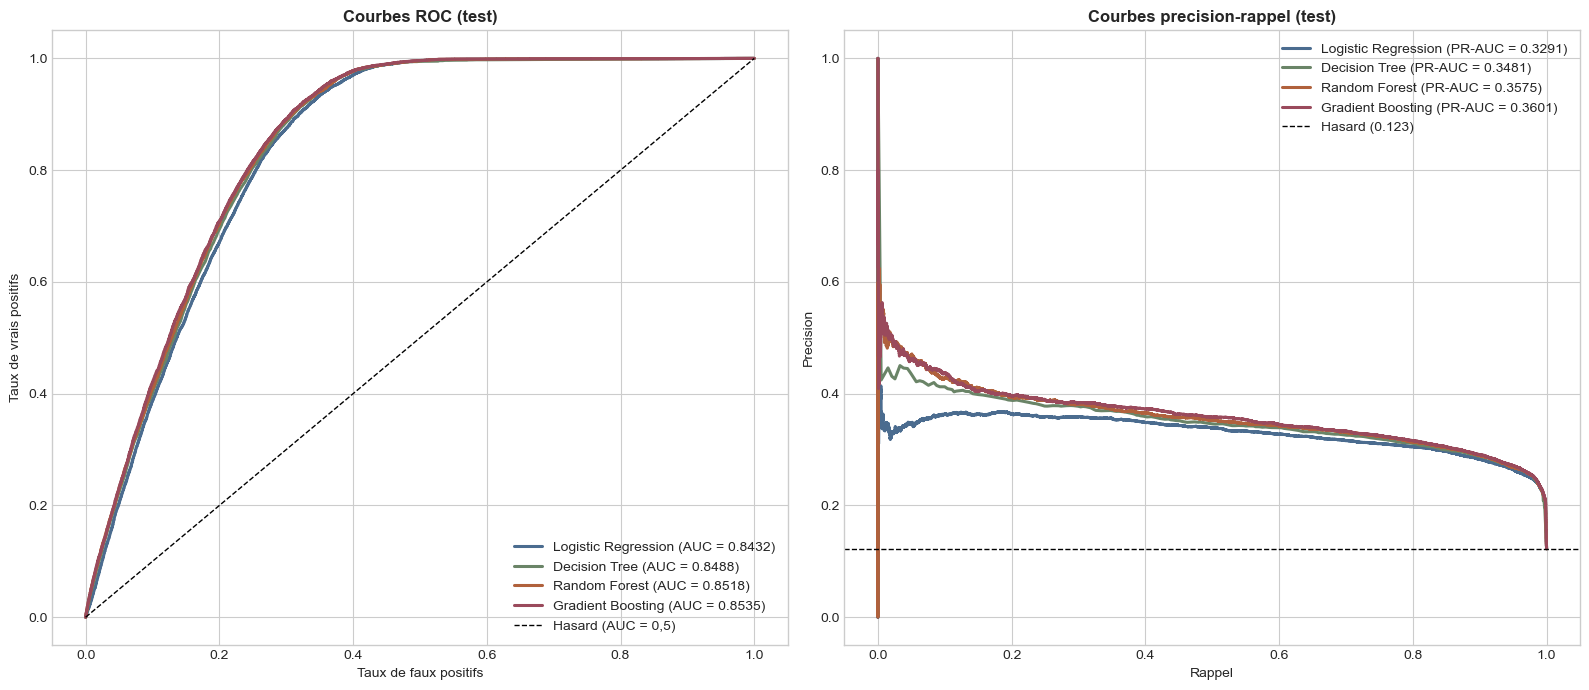

In [33]:
# ============================================================
# 10.2 COURBES ROC ET PRECISION-RAPPEL
# ============================================================
colors = {'Logistic Regression': '#4b6c8f', 'Decision Tree': '#6a8467',
          'Random Forest': '#b0613c', 'Gradient Boosting': '#9a4a5c'}
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for name, prob in probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, color=colors[name], lw=2.2, label=f'{name} (AUC = {roc_auc_score(y_test, prob):.4f})')
    prec, rec, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(rec, prec, color=colors[name], lw=2.2,
                 label=f'{name} (PR-AUC = {average_precision_score(y_test, prob):.4f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Hasard (AUC = 0,5)')
axes[0].set_xlabel('Taux de faux positifs')
axes[0].set_ylabel('Taux de vrais positifs')
axes[0].set_title('Courbes ROC (test)', fontweight='bold')
axes[1].axhline(y_test.mean(), color='k', ls='--', lw=1, label=f'Hasard ({y_test.mean():.3f})')
axes[1].set_xlabel('Rappel')
axes[1].set_ylabel('Precision')
axes[1].set_title('Courbes precision-rappel (test)', fontweight='bold')
for ax in axes:
    ax.legend(loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout()
plt.savefig('roc_curves_final.png', dpi=150, bbox_inches='tight')
plt.show()

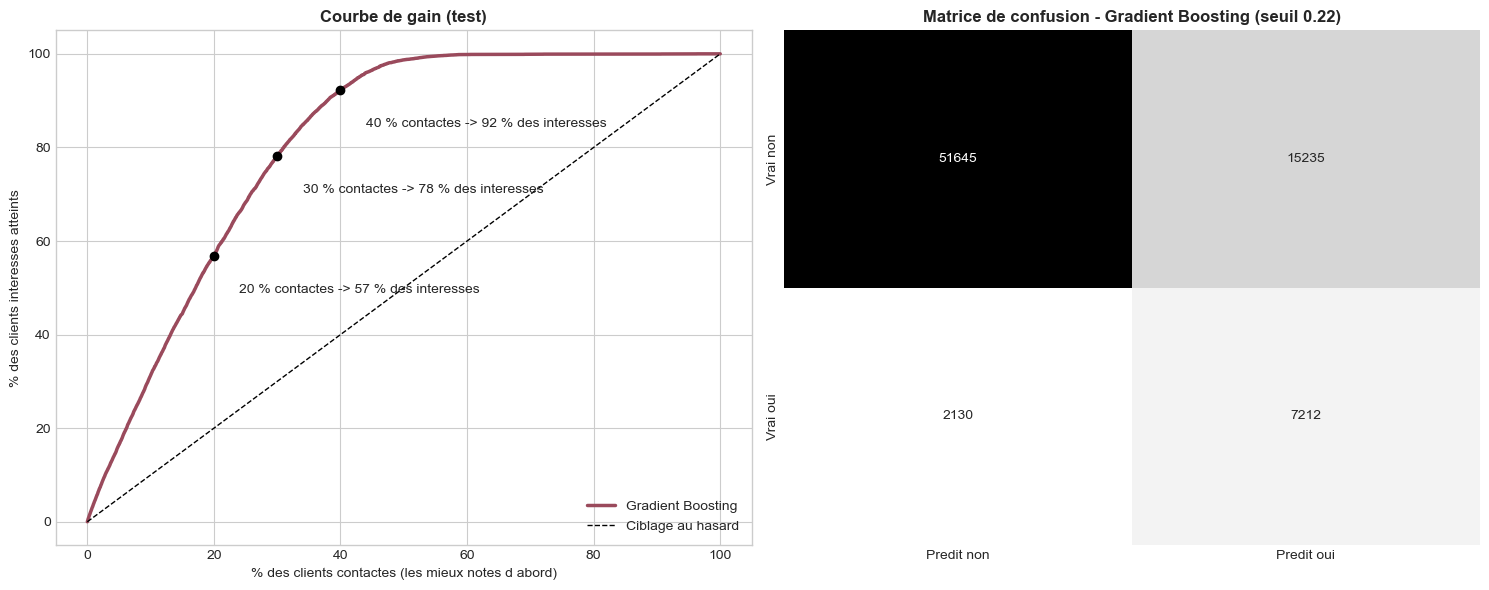

En contactant 20 % des clients : 56.9 % des interesses atteints
En contactant 30 % des clients : 78.2 % des interesses atteints
En contactant 40 % des clients : 92.3 % des interesses atteints


In [34]:
# ============================================================
# 10.3 USAGE METIER : COURBE DE GAIN ET MATRICE DE CONFUSION
# ============================================================
prob = probabilities[best_name]
order = np.argsort(-prob)
captured = np.cumsum(y_test.values[order]) / y_test.sum()
share = np.arange(1, len(prob) + 1) / len(prob)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(share * 100, captured * 100, color='#9a4a5c', lw=2.5, label=best_name)
axes[0].plot([0, 100], [0, 100], 'k--', lw=1, label='Ciblage au hasard')
for p in (20, 30, 40):
    c = captured[int(len(prob) * p / 100) - 1] * 100
    axes[0].scatter(p, c, color='black', zorder=3)
    axes[0].annotate(f'{p} % contactes -> {c:.0f} % des interesses', (p, c), xytext=(p + 4, c - 8))
axes[0].set_xlabel('% des clients contactes (les mieux notes d abord)')
axes[0].set_ylabel('% des clients interesses atteints')
axes[0].set_title('Courbe de gain (test)', fontweight='bold')
axes[0].legend(loc='lower right')

cm = confusion_matrix(y_test, (prob >= best_thr).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False, ax=axes[1],
            xticklabels=['Predit non', 'Predit oui'], yticklabels=['Vrai non', 'Vrai oui'])
axes[1].set_title(f'Matrice de confusion - {best_name} (seuil {best_thr:.2f})', fontweight='bold')
plt.tight_layout()
plt.savefig('gain_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

for p in (20, 30, 40):
    print(f'En contactant {p} % des clients : {captured[int(len(prob) * p / 100) - 1] * 100:.1f} % des interesses atteints')

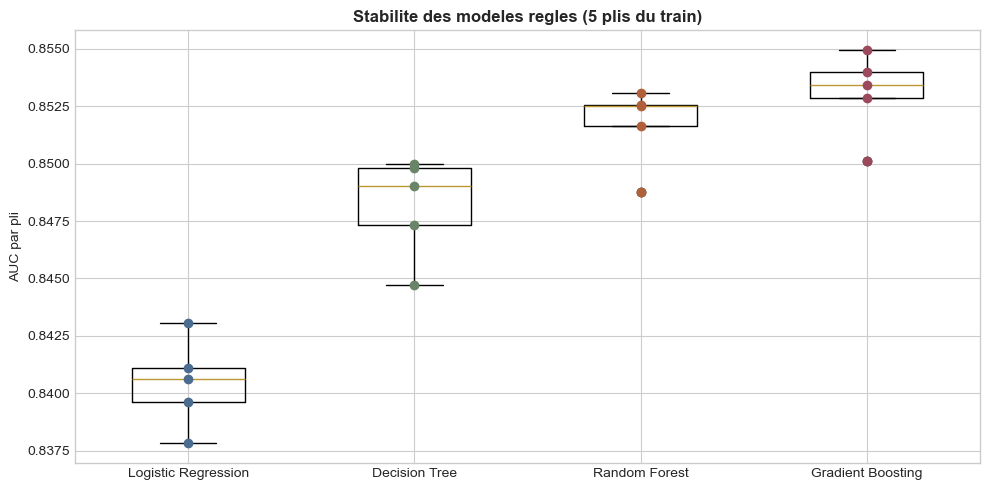

       Logistic Regression  Decision Tree  Random Forest  Gradient Boosting
pli 1               0.8431         0.8500         0.8531             0.8549
pli 2               0.8411         0.8498         0.8526             0.8540
pli 3               0.8406         0.8490         0.8525             0.8534
pli 4               0.8396         0.8473         0.8516             0.8528
pli 5               0.8378         0.8447         0.8488             0.8501


In [35]:
# ============================================================
# 10.4 STABILITE : AUC PAR PLI (validation croisee 5 plis)
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([cv_fold_auc[m] for m in cv_fold_auc], labels=list(cv_fold_auc), widths=0.5)
for i, m in enumerate(cv_fold_auc, 1):
    ax.scatter(np.full(5, i), cv_fold_auc[m], color=colors[m], zorder=3)
ax.set_ylabel('AUC par pli')
ax.set_title('Stabilite des modeles regles (5 plis du train)', fontweight='bold')
plt.tight_layout()
plt.savefig('cv_stability.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.DataFrame({m: a for m, a in cv_fold_auc.items()}, index=[f'pli {i}' for i in range(1, 6)]).round(4).to_string())

## 11. Conclusion

| Modèle | AUC (validation croisée) | AUC test | Rappel | Précision |
|---|---|---|---|---|
| Régression logistique | 0,841 | 0,843 | 0,80 | 0,31 |
| Arbre de décision | 0,848 | 0,849 | 0,77 | 0,32 |
| Forêt aléatoire | 0,852 | 0,852 | 0,78 | 0,32 |
| **Gradient Boosting** | **0,853** | **0,854** | 0,77 | 0,32 |

- Le **Gradient Boosting** est le meilleur modèle, avec un écart de 0,013 seulement sur la régression logistique. Si la lisibilité prime, la régression logistique reste un très bon choix.
- **Usage métier** : en contactant seulement 30 % des clients, les mieux notés, on atteint **78 % des intéressés**. Avec 40 % des clients, on en atteint 92 %.
- **Ce qui a changé par rapport à la première version** :
  - le jeu de test n'est plus utilisé pour faire des choix ;
  - le rééquilibrage est appliqué à l'intérieur de la validation croisée ;
  - les variables sont choisies par une méthode propre à chaque modèle ;
  - chaque modèle est réglé dans sa meilleure version ;
  - le seuil de décision est choisi sur le train ;
  - une graine unique rend les résultats reproductibles.

  Les scores sont un peu plus modestes, mais ils sont honnêtes.